# ViralMetrics: Decoding What Makes Content Take Off

**Team:** Phoo Pwint Cho Thar (67011755) · Bhawat Kolkitchaiwan (67011087) · Thiri Thaw (67011731) · San Aung (67011725)

**Research question:** *Which measurable content and posting features most strongly predict whether a piece of content goes viral — and can we turn that into honest, testable recommendations?*

**Dataset:** [Online News Popularity — UCI Machine Learning Repository (id 332)](https://archive.ics.uci.edu/dataset/332/online+news+popularity)

- 39,644 real articles published by Mashable, January 2013 – December 2014 (Fernandes et al., 2015).
- About 58 features known **at publishing time**: day of week, topic, title and article length, images, videos, links, keywords, sentiment.
- Target `shares`: how many times each article was shared on social networks.
- Chosen because it is real, large, has the long-tailed shape of genuine social data, and records choices a creator controls.

**How to run:** *Runtime → Run all* in Google Colab (≈ 15 minutes on the free tier). The data downloads automatically from UCI; if the download fails, put `OnlineNewsPopularity.csv` in a `data/` folder. No manual editing of data is needed.

**Notebook sections follow the report sections:**

| # | Section | # | Section |
|---|---|---|---|
| 1 | Executive summary (printed in §10.2) | 6 | Method / modelling |
| 2 | Problem & objectives | 7 | Results & evaluation |
| 3 | Data understanding | 8 | Interpretation & insights |
| 4 | Data preparation | 9 | Recommendations |
| 5 | Exploratory data analysis | 10 | Limitations & conclusion |

## 2. Problem & objectives

**Target.** An article is **viral** if its shares are in the **top 20 %** of the training period. The threshold is learned on training data only. Predicting "takes off or not" is better than predicting the exact share count, which a few huge outliers dominate.

**Success criteria**

1. **Adds value** — beats both no-skill baselines on PR-AUC (no skill ≈ 0.20) and ROC-AUC (no skill = 0.5) in 5-fold CV, by more than one standard deviation.
2. **Holds on new data** — still beats the baselines on a later time period.
3. **Not luck** — a model trained on shuffled labels falls back to the baseline.
4. **Trustworthy recommendation** — significant in the training period after Bonferroni correction, *and* the same direction in the test period.

In [ ]:
import os, io, json, zipfile, urllib.request, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency

from sklearn.model_selection import (StratifiedKFold, cross_validate, cross_val_predict,
                                     RandomizedSearchCV, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              HistGradientBoostingRegressor)
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, accuracy_score, confusion_matrix, roc_curve,
                             precision_recall_curve, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.inspection import PartialDependenceDisplay
from sklearn.calibration import calibration_curve

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)
sns.set_style('whitegrid')

FIG_DIR, RES_DIR = 'figures', 'results'
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)
RESULTS = {}

def save_fig(name):
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')

print('Setup complete. scikit-learn', __import__('sklearn').__version__)

Setup complete. scikit-learn 1.6.1


## 3. Data understanding

### 3.1 Loading the data

In [ ]:
DATA_URL = 'https://archive.ics.uci.edu/static/public/332/online+news+popularity.zip'
LOCAL_CANDIDATES = ['data/OnlineNewsPopularity.csv', 'OnlineNewsPopularity.csv',
                    'data/OnlineNewsPopularity/OnlineNewsPopularity.csv']

def load_raw():
    for path in LOCAL_CANDIDATES:
        if os.path.exists(path):
            return pd.read_csv(path), path
    os.makedirs('data', exist_ok=True)
    zip_path = 'data/online_news_popularity.zip'
    print('Downloading from UCI ...')
    urllib.request.urlretrieve(DATA_URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        name = [n for n in z.namelist() if n.endswith('OnlineNewsPopularity.csv')][0]
        z.extract(name, 'data')
    path = os.path.join('data', name)
    return pd.read_csv(path), path

raw, source_path = load_raw()
raw.columns = raw.columns.str.strip()          # the original file has a leading space in every column name
print('Loaded from:', source_path)
print('Shape:', raw.shape)
assert raw.shape == (39644, 61), 'Unexpected file — check that this is the UCI Online News Popularity CSV'
raw.head(3)

Loaded from: data/OnlineNewsPopularity/OnlineNewsPopularity.csv
Shape: (39644, 61)


,url,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,average_token_length,num_keywords,data_channel_is_lifestyle,data_channel_is_entertainment,data_channel_is_bus,data_channel_is_socmed,data_channel_is_tech,data_channel_is_world,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg,self_reference_min_shares,self_reference_max_shares,...,weekday_is_monday,weekday_is_tuesday,weekday_is_wednesday,weekday_is_thursday,weekday_is_friday,weekday_is_saturday,weekday_is_sunday,is_weekend,LDA_00,LDA_01,LDA_02,LDA_03,LDA_04,global_subjectivity,global_sentiment_polarity,global_rate_positive_words,global_rate_negative_words,rate_positive_words,rate_negative_words,avg_positive_polarity,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,0.0,4.680365,5.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,496.0,496.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.500331,0.378279,0.040005,0.041263,0.040123,0.521617,0.092562,0.045662,0.013699,0.769231,0.230769,0.378636,0.100000,0.7,-0.350000,-0.600,-0.200000,0.5,-0.1875,0.0,0.1875,593
1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,0.0,4.913725,4.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.799756,0.050047,0.050096,0.050101,0.050001,0.341246,0.148948,0.043137,0.015686,0.733333,0.266667,0.286915,0.033333,0.7,-0.118750,-0.125,-0.100000,0.0,0.0000,0.5,0.0000,711
2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,0.0,4.393365,6.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,918.0,918.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.217792,0.033334,0.033351,0.033334,0.682188,0.702222,0.323333,0.056872,0.009479,0.857143,0.142857,0.495833,0.100000,1.0,-0.466667,-0.800,-0.133333,0.0,0.0000,0.5,0.0000,1500


### 3.2 Variables, target and data quality

In [ ]:
groups = {
    'Identifier / timing (not features)': ['url', 'timedelta'],
    'Length & structure': ['n_tokens_title', 'n_tokens_content', 'n_unique_tokens', 'n_non_stop_words',
                           'n_non_stop_unique_tokens', 'average_token_length'],
    'Links & media': ['num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos'],
    'Keywords (count)': ['num_keywords'],
    'Topic channel (one-hot)': [c for c in raw.columns if c.startswith('data_channel_is_')],
    'Publish weekday (one-hot)': [c for c in raw.columns if c.startswith('weekday_is_')] + ['is_weekend'],
    'Topic mix (LDA)': [c for c in raw.columns if c.startswith('LDA_')],
    'Sentiment & subjectivity': ['global_subjectivity', 'global_sentiment_polarity', 'global_rate_positive_words',
                                 'global_rate_negative_words', 'rate_positive_words', 'rate_negative_words',
                                 'avg_positive_polarity', 'min_positive_polarity', 'max_positive_polarity',
                                 'avg_negative_polarity', 'min_negative_polarity', 'max_negative_polarity',
                                 'title_subjectivity', 'title_sentiment_polarity', 'abs_title_subjectivity',
                                 'abs_title_sentiment_polarity'],
    'Platform history: keyword shares': [c for c in raw.columns if c.startswith('kw_')],
    'Platform history: self-reference shares': [c for c in raw.columns if c.startswith('self_reference_')],
    'Target': ['shares'],
}
assert sum(len(v) for v in groups.values()) == raw.shape[1]
var_table = pd.DataFrame([(g, len(c), ', '.join(c[:4]) + (' ...' if len(c) > 4 else '')) for g, c in groups.items()],
                         columns=['Variable group', '# columns', 'Examples'])
display(var_table)

,Variable group,# columns,Examples
0,Identifier / timing (not features),2,"url, timedelta"
1,Length & structure,6,"n_tokens_title, n_tokens_content, n_unique_tok..."
2,Links & media,4,"num_hrefs, num_self_hrefs, num_imgs, num_videos"
3,Keywords (count),1,num_keywords
4,Topic channel (one-hot),6,"data_channel_is_lifestyle, data_channel_is_ent..."
5,Publish weekday (one-hot),8,"weekday_is_monday, weekday_is_tuesday, weekday..."
6,Topic mix (LDA),5,"LDA_00, LDA_01, LDA_02, LDA_03 ..."
7,Sentiment & subjectivity,16,"global_subjectivity, global_sentiment_polarity..."
8,Platform history: keyword shares,9,"kw_min_min, kw_max_min, kw_avg_min, kw_min_max..."
9,Platform history: self-reference shares,3,"self_reference_min_shares, self_reference_max_..."


In [ ]:
print('Missing values (total):', int(raw.isna().sum().sum()))
print('Duplicate rows:', int(raw.duplicated().sum()), '| duplicate URLs:', int(raw['url'].duplicated().sum()))
print('Data types:', raw.dtypes.value_counts().to_dict())
print()
print('Target `shares`:')
print(raw['shares'].describe(percentiles=[.25, .5, .75, .8, .9, .99]).round(1).to_string())
print(f"Skewness: {raw['shares'].skew():.1f}  (0 = symmetric)")

Missing values (total): 0
Duplicate rows: 0 | duplicate URLs: 0
Data types: {dtype('float64'): 59, dtype('O'): 1, dtype('int64'): 1}

Target `shares`:
count     39644.0
mean       3395.4
std       11627.0
min           1.0
25%         946.0
50%        1400.0
75%        2800.0
80%        3400.0
90%        6200.0
99%       31657.0
max      843300.0
Skewness: 34.0  (0 = symmetric)


In [ ]:
# Data-quality checks: values that are impossible or suspicious
dq = pd.DataFrame({
    'check': ['Articles with 0 words of content', 'n_unique_tokens > 1 (impossible ratio)',
              'n_non_stop_words: share of rows equal to 1.0', 'kw_min_min == -1 (sentinel value)',
              'kw_avg_min == -1 (sentinel value)', 'kw_min_avg == -1 (sentinel value)',
              'Rows where no topic channel flag is set'],
    'count_or_value': [int((raw['n_tokens_content'] == 0).sum()), int((raw['n_unique_tokens'] > 1).sum()),
                       round(float((raw['n_non_stop_words'].round(6) == 1).mean()), 3),
                       int((raw['kw_min_min'] == -1).sum()), int((raw['kw_avg_min'] == -1).sum()),
                       int((raw['kw_min_avg'] == -1).sum()),
                       int((raw[groups['Topic channel (one-hot)']].sum(axis=1) == 0).sum())],
})
display(dq)

,check,count_or_value
0,Articles with 0 words of content,1181.00
1,n_unique_tokens > 1 (impossible ratio),1.00
2,n_non_stop_words: share of rows equal to 1.0,0.97
3,kw_min_min == -1 (sentinel value),22980.00
4,kw_avg_min == -1 (sentinel value),694.00
5,kw_min_avg == -1 (sentinel value),6.00
6,Rows where no topic channel flag is set,6134.00


### 3.3 Data quality issues and how we handle them

| Issue | Evidence | Handling |
|---|---|---|
| Missing values / duplicates | 0 missing cells, 0 duplicate URLs | Nothing to impute or remove |
| Impossible word ratio | `n_unique_tokens` > 1 in 1 row | Removed (data-entry error) |
| Articles with no text | 1,181 articles have 0 content words, so their text features are all 0 | Kept (real image / video posts) and flagged with `no_text` |
| Near-constant column | `n_non_stop_words` = 1.0 for 97 % of rows | Dropped |
| Sentinel values | `kw_*` columns use −1 for "no data" (22,980 rows in `kw_min_min`) | Only used in the platform-history comparison |
| No topic label | 6,134 articles have no channel flag | Given the explicit category `Other` |
| Extremely skewed target | Skewness 34; median 1,400 shares, max 843,300 | Not capped (the tail *is* virality); we predict "top 20 %" instead |
| No posting hour | Only the date is available (from the URL) | "Best hour to post" cannot be tested — a limitation |

## 4. Data preparation

Each step prints the data shape before and after, so the trail is auditable.

1. **Dates** — parse the publication date from the URL and compare it with the weekday flags.
2. **Cleaning** — remove the impossible row, drop the near-constant column, add the `no_text` flag.
3. **Readable labels** — `channel` and `weekday` columns for charts only (models use the original 0/1 flags).
4. **Time-based split** — train on older articles, test on the most recent ~20 %. This copies real use (learn from the past, predict new posts) and is stricter than a random split.
5. **Target** — `viral` = shares ≥ the 80th percentile of the *training* period.
6. **Feature sets** — creator-controllable vs. full (+ platform history), with a leakage guard.

> **Result:** 39,643 articles after cleaning · training 31,637 (Jan 2013 – Aug 2014, 20.5 % viral) · test 8,006 (Aug – Dec 2014, 16.6 % viral) · viral threshold 3,500 shares.
>
> **Note:** the URL date matches the weekday flag for 76 % of articles and is usually one day earlier for the rest (likely draft vs. publish time), so we keep the dataset's own weekday flags. Test articles had been online a median 72 days when collected vs 427 for training articles, which partly explains their lower viral rate.

In [ ]:
df = raw.copy()
print('Before:', df.shape)

# 1. Publication date from URL, e.g. http://mashable.com/2013/01/07/...
df['pub_date'] = pd.to_datetime(df['url'].str.extract(r'mashable\.com/(\d{4}/\d{2}/\d{2})/')[0], format='%Y/%m/%d')
assert df['pub_date'].notna().all()
weekday_cols = ['weekday_is_monday', 'weekday_is_tuesday', 'weekday_is_wednesday', 'weekday_is_thursday',
                'weekday_is_friday', 'weekday_is_saturday', 'weekday_is_sunday']
flag_day = df[weekday_cols].values.argmax(axis=1)
agree = (flag_day == df['pub_date'].dt.dayofweek.values).mean()
print(f'Weekday from URL date agrees with weekday flags for {agree:.1%} of articles')
print('Date range:', df['pub_date'].min().date(), 'to', df['pub_date'].max().date())

# 2. Cleaning
bad = df['n_unique_tokens'] > 1
print('Removing impossible rows:', int(bad.sum()))
df = df.loc[~bad].copy()
df = df.drop(columns=['n_non_stop_words'])
df['no_text'] = (df['n_tokens_content'] == 0).astype(int)

# 3. Readable categories for EDA
channel_cols = [c for c in df.columns if c.startswith('data_channel_is_')]
names = {'lifestyle': 'Lifestyle', 'entertainment': 'Entertainment', 'bus': 'Business', 'socmed': 'Social Media',
         'tech': 'Tech', 'world': 'World'}
df['channel'] = 'Other'
for c in channel_cols:
    df.loc[df[c] == 1, 'channel'] = names[c.replace('data_channel_is_', '')]
df['data_channel_is_other'] = (df['channel'] == 'Other').astype(int)
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
df['weekday'] = pd.Categorical([day_names[i] for i in df[weekday_cols].values.argmax(axis=1)], categories=day_names, ordered=True)
df['log_shares'] = np.log1p(df['shares'])
print('After:', df.shape)

Before: (39644, 61)
Weekday from URL date agrees with weekday flags for 76.1% of articles
Date range: 2013-01-07 to 2014-12-27
Removing impossible rows: 1
After: (39643, 66)


In [ ]:
# 4. Chronological split: the most recent ~20% of articles (by publication date) form the test set
df = df.sort_values('pub_date').reset_index(drop=True)
cutoff = df['pub_date'].quantile(0.80)
train_df = df[df['pub_date'] < cutoff].copy()
test_df = df[df['pub_date'] >= cutoff].copy()
print(f'Cut-off date: {cutoff.date()}')
print(f'Train: {len(train_df):,} articles ({train_df.pub_date.min().date()} to {train_df.pub_date.max().date()})')
print(f'Test : {len(test_df):,} articles ({test_df.pub_date.min().date()} to {test_df.pub_date.max().date()})')

# 5. Viral threshold learned on TRAIN only, then applied to both
VIRAL_THRESHOLD = train_df['shares'].quantile(0.80)
for d in (train_df, test_df, df):
    d['viral'] = (d['shares'] >= VIRAL_THRESHOLD).astype(int)
print(f'\nViral threshold (80th percentile of training shares): {VIRAL_THRESHOLD:,.0f} shares')
print(f"Viral rate — train: {train_df['viral'].mean():.3f} | test: {test_df['viral'].mean():.3f}")
print(f"Median shares — train: {train_df['shares'].median():,.0f} | test: {test_df['shares'].median():,.0f}")
print(f"Median days online when collected (timedelta) — train: {train_df['timedelta'].median():.0f} | test: {test_df['timedelta'].median():.0f}")
RESULTS['split'] = {'cutoff': str(cutoff.date()), 'n_train': len(train_df), 'n_test': len(test_df),
                    'viral_threshold': float(VIRAL_THRESHOLD),
                    'viral_rate_train': float(train_df['viral'].mean()), 'viral_rate_test': float(test_df['viral'].mean())}

Cut-off date: 2014-08-28
Train: 31,637 articles (2013-01-07 to 2014-08-27)
Test : 8,006 articles (2014-08-28 to 2014-12-27)

Viral threshold (80th percentile of training shares): 3,500 shares
Viral rate — train: 0.205 | test: 0.166
Median shares — train: 1,500 | test: 1,300
Median days online when collected (timedelta) — train: 427 | test: 72


In [ ]:
# 6. Feature sets
HISTORY = [c for c in df.columns if c.startswith('kw_') or c.startswith('self_reference_')]
EXCLUDE = {'url', 'timedelta', 'shares', 'log_shares', 'viral', 'pub_date', 'channel', 'weekday'}
CONTROLLABLE = [c for c in df.columns if c not in EXCLUDE and c not in HISTORY]
FULL = CONTROLLABLE + HISTORY
print(f'Creator-controllable features: {len(CONTROLLABLE)}')
print(f'Platform-history features    : {len(HISTORY)}')
print(f'Full feature set             : {len(FULL)}')

# Leakage guard: none of the post-publication or identifier columns may be a feature
assert not (set(FULL) & EXCLUDE), 'Leakage: an excluded column is in the feature list'

# Count-like columns are log-transformed for the linear model only (trees do not need it)
LOG_COLS = ['n_tokens_title', 'n_tokens_content', 'num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos'] + HISTORY
X_train_c, X_test_c = train_df[CONTROLLABLE], test_df[CONTROLLABLE]
X_train_f, X_test_f = train_df[FULL], test_df[FULL]
y_train, y_test = train_df['viral'].values, test_df['viral'].values
RESULTS['features'] = {'controllable': CONTROLLABLE, 'history': HISTORY}

Creator-controllable features: 47
Platform-history features    : 12
Full feature set             : 59


## 5. Exploratory data analysis

All charts use the **training period only**; the test period is kept for confirming findings later.

**How to read the viral-rate charts:** each bar is the share of articles that went viral, the black lines are 95 % confidence intervals, and the dashed red line is the overall rate (20.5 %). Each chart is followed by *Question → Evidence → Observation → Interpretation*.

In [ ]:
BASE_RATE = train_df['viral'].mean()

def rate_table(data, col):
    g = data.groupby(col, observed=True)['viral'].agg(viral_rate='mean', n='count')
    se = np.sqrt(g['viral_rate'] * (1 - g['viral_rate']) / g['n'])
    g['ci_low'], g['ci_high'] = g['viral_rate'] - 1.96 * se, g['viral_rate'] + 1.96 * se
    return g

def chi2_p(data, col):
    return chi2_contingency(pd.crosstab(data[col], data['viral']))[1]

def plot_rate(g, title, xlabel, fname, ax=None, color='#1f9e89'):
    ax = ax or plt.subplots(figsize=(8, 4.5))[1]
    x = np.arange(len(g))
    ax.bar(x, g['viral_rate'], color=color, alpha=.85)
    ax.errorbar(x, g['viral_rate'], yerr=[g['viral_rate'] - g['ci_low'], g['ci_high'] - g['viral_rate']],
                fmt='none', ecolor='#333', capsize=4)
    ax.axhline(BASE_RATE, ls='--', color='#e05a5a', label=f'Overall {BASE_RATE:.0%}')
    ax.set_xticks(x); ax.set_xticklabels([f'{i}\n(n={n:,})' for i, n in zip(g.index, g['n'])], fontsize=9)
    ax.set_ylabel('Share of articles that went viral'); ax.set_xlabel(xlabel); ax.set_title(title)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}')); ax.legend()
    return ax

# Binned versions of the creator choices (bins chosen for readability, fixed before looking at outcomes)
def add_bins(d):
    d['img_bin'] = pd.cut(d['num_imgs'], [-1, 0, 1, 5, 10, 1e9], labels=['0', '1', '2-5', '6-10', '11+'])
    d['video_bin'] = pd.cut(d['num_videos'], [-1, 0, 1, 1e9], labels=['0', '1', '2+'])
    d['title_bin'] = pd.cut(d['n_tokens_title'], [0, 7, 10, 13, 100], labels=['<=7', '8-10', '11-13', '14+'])
    d['length_bin'] = pd.cut(d['n_tokens_content'], [-1, 0, 250, 500, 1000, 1e9],
                             labels=['no text', '1-250', '251-500', '501-1000', '1000+'])
    d['link_bin'] = pd.cut(d['num_hrefs'], [-1, 3, 7, 15, 1e9], labels=['0-3', '4-7', '8-15', '16+'])
    d['subj_bin'] = pd.cut(d['global_subjectivity'], [-0.01, 0.35, 0.45, 0.55, 1.0],
                           labels=['<0.35', '0.35-0.45', '0.45-0.55', '>0.55'])
    d['day_type'] = np.where(d['is_weekend'] == 1, 'Weekend', 'Weekday')
    return d
for d in (train_df, test_df):
    add_bins(d)
print('Overall training viral rate:', round(BASE_RATE, 3))

Overall training viral rate: 0.205


### 5.1 How are shares distributed?

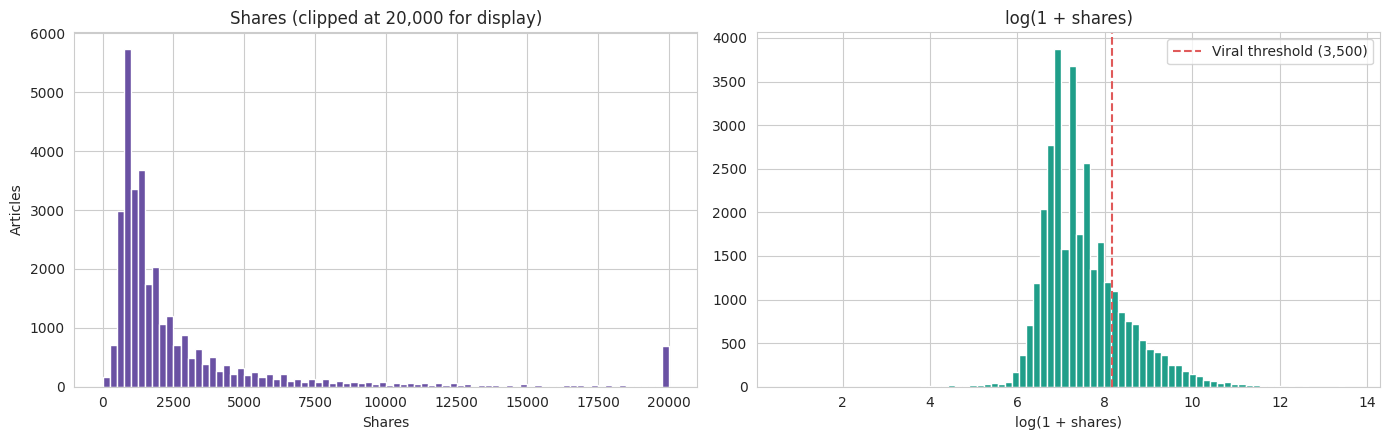

Top 1% of articles (>= 31,500 shares) collect 22.0% of all shares


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(train_df['shares'].clip(upper=20000), bins=80, color='#6a51a3')
axes[0].set_title('Shares (clipped at 20,000 for display)'); axes[0].set_xlabel('Shares'); axes[0].set_ylabel('Articles')
axes[1].hist(train_df['log_shares'], bins=80, color='#1f9e89')
axes[1].axvline(np.log1p(VIRAL_THRESHOLD), color='#e05a5a', ls='--', label=f'Viral threshold ({VIRAL_THRESHOLD:,.0f})')
axes[1].set_title('log(1 + shares)'); axes[1].set_xlabel('log(1 + shares)'); axes[1].legend()
plt.tight_layout(); save_fig('eda_shares_distribution'); plt.show()
top1 = train_df['shares'].quantile(.99)
share_of_top1 = train_df.loc[train_df['shares'] >= top1, 'shares'].sum() / train_df['shares'].sum()
print(f'Top 1% of articles (>= {top1:,.0f} shares) collect {share_of_top1:.1%} of all shares')

- **Question:** Are shares distributed like real social data, or evenly like our first dataset?
- **Evidence:** Histograms of raw shares and of log(1 + shares).
- **Observation:** Shares are extremely right-skewed (skewness 34). The median training article gets 1,500 shares, but the top 1 % (≥ 31,500 shares) collect 22 % of all shares. On the log scale the shape is roughly bell-shaped.
- **Interpretation:** This is the long tail expected from real social media, so the data passes the realism check our first dataset failed. Because a few articles dominate totals, we compare **viral rates**, not average shares.

### 5.2 Does the day of publication matter?

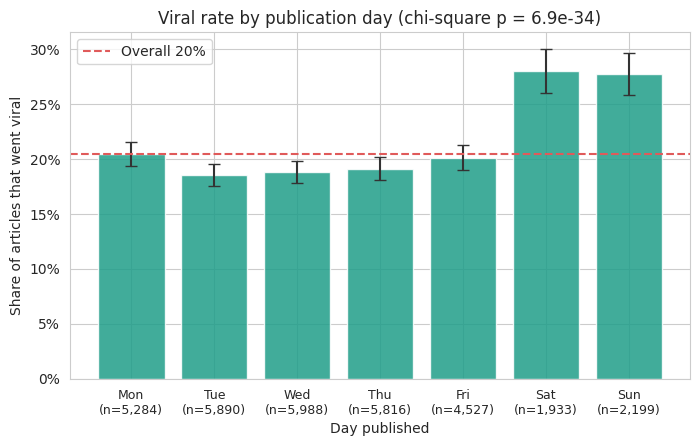

,viral_rate,n,ci_low,ci_high
weekday,,,,
Mon,0.204,5284,0.194,0.215
Tue,0.186,5890,0.176,0.195
Wed,0.188,5988,0.178,0.198
Thu,0.191,5816,0.181,0.201
Fri,0.201,4527,0.190,0.213
Sat,0.280,1933,0.260,0.300
Sun,0.277,2199,0.259,0.296


In [ ]:
g_day = rate_table(train_df, 'weekday')
p_day = chi2_p(train_df, 'weekday')
plot_rate(g_day, f'Viral rate by publication day (chi-square p = {p_day:.1e})', 'Day published', 'eda_weekday')
save_fig('eda_weekday'); plt.show()
display(g_day.round(3))

- **Question:** Is "timing matters" true at the level of day of week?
- **Evidence:** Viral rate by publication day with 95 % CIs; chi-square test.
- **Observation:** Weekend articles go viral far more often: **28.0 % on Saturday and 27.7 % on Sunday** vs 18.6–20.4 % on weekdays. The intervals do not overlap (p = 6.9 × 10⁻³⁴).
- **Interpretation:** A weekend article is about **1.4× as likely** to go viral. A plausible reason is less competition — only about 13 % of articles are published at weekends. This is association, not cause; §5.7 checks whether topic explains it.

### 5.3 Does the topic matter?

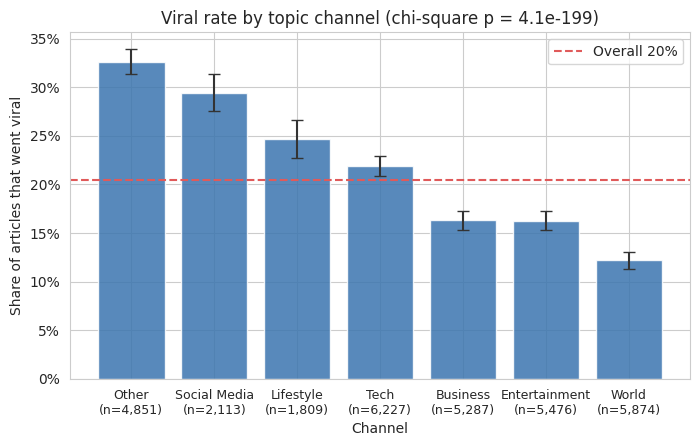

,viral_rate,n,ci_low,ci_high
channel,,,,
Other,0.326,4851,0.313,0.340
Social Media,0.294,2113,0.275,0.314
Lifestyle,0.247,1809,0.227,0.266
Tech,0.218,6227,0.208,0.229
Business,0.163,5287,0.153,0.173
Entertainment,0.163,5476,0.153,0.172
World,0.122,5874,0.113,0.130


In [ ]:
g_ch = rate_table(train_df, 'channel').sort_values('viral_rate', ascending=False)
p_ch = chi2_p(train_df, 'channel')
plot_rate(g_ch, f'Viral rate by topic channel (chi-square p = {p_ch:.1e})', 'Channel', 'eda_channel', color='#3b75af')
save_fig('eda_channel'); plt.show()
display(g_ch.round(3))

- **Question:** Do some topics go viral more often than others?
- **Evidence:** Viral rate by Mashable channel with 95 % CIs; chi-square test.
- **Observation:** Rates range from **12.2 % (World)** to **29.4 % (Social Media)** and 32.6 % for unlabelled articles (`Other`). Lifestyle 24.7 %, Tech 21.8 %, Business and Entertainment 16.3 % (p = 4 × 10⁻¹⁹⁹ — the strongest test).
- **Interpretation:** Topic is the strongest pre-posting signal. Channels also differ in publishing day and media use, so topic could **confound** the other effects — checked in §5.7 and §8.3.

### 5.4 Do images and videos help?

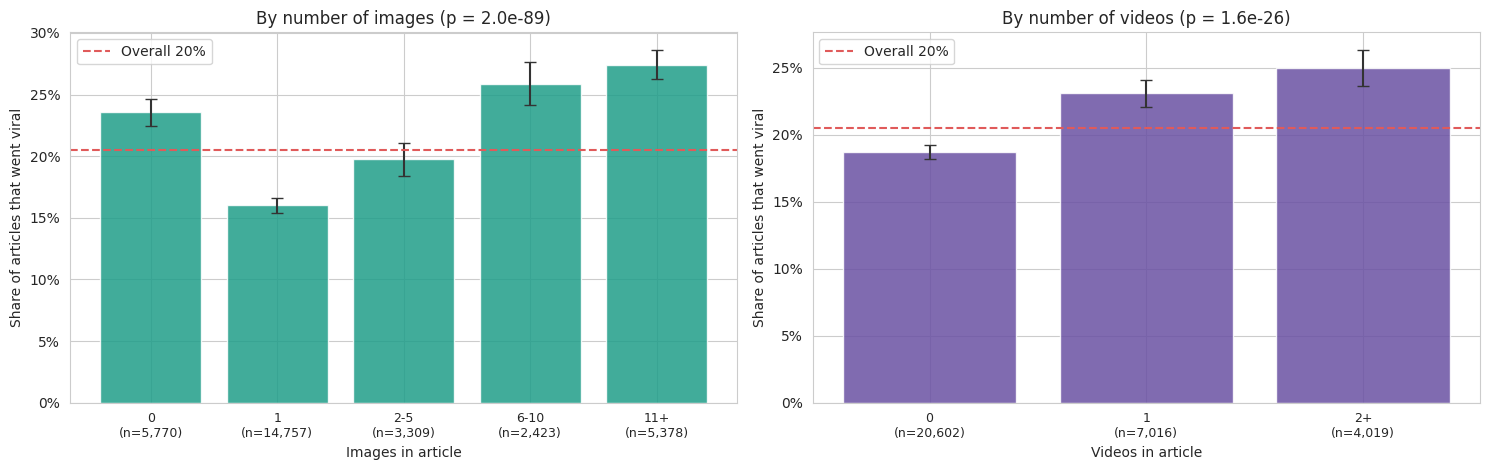

viral_rate      n  ci_low  ci_high
images 0          0.236   5770   0.225    0.247
       1          0.160  14757   0.154    0.166
       2-5        0.197   3309   0.184    0.211
       6-10       0.259   2423   0.241    0.276
       11+        0.274   5378   0.262    0.286
videos 0          0.187  20602   0.182    0.192
       1          0.231   7016   0.221    0.241
       2+         0.250   4019   0.236    0.263

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
g_img = rate_table(train_df, 'img_bin'); p_img = chi2_p(train_df, 'img_bin')
g_vid = rate_table(train_df, 'video_bin'); p_vid = chi2_p(train_df, 'video_bin')
plot_rate(g_img, f'By number of images (p = {p_img:.1e})', 'Images in article', None, ax=axes[0])
plot_rate(g_vid, f'By number of videos (p = {p_vid:.1e})', 'Videos in article', None, ax=axes[1], color='#6a51a3')
plt.tight_layout(); save_fig('eda_media'); plt.show()
display(pd.concat({'images': g_img, 'videos': g_vid}).round(3))

- **Question:** Does visual media relate to going viral?
- **Evidence:** Viral rate by number of images and videos with 95 % CIs; chi-square tests.
- **Observation:** **Images are U-shaped:** exactly 1 image is worst (16.0 %), image-rich articles are best (6–10 images 25.9 %, 11+ images 27.4 %), no images 23.6 %. **Videos: more is better** — 18.7 % (none), 23.1 % (one), 25.0 % (two or more). Both p < 10⁻²⁵.
- **Interpretation:** "Add an image" is too simple: one obligatory header image is the typical low-effort format and does worst, while galleries and image-rich lists do best. Video is consistently linked to more viral articles.

### 5.5 Do title length and article length matter?

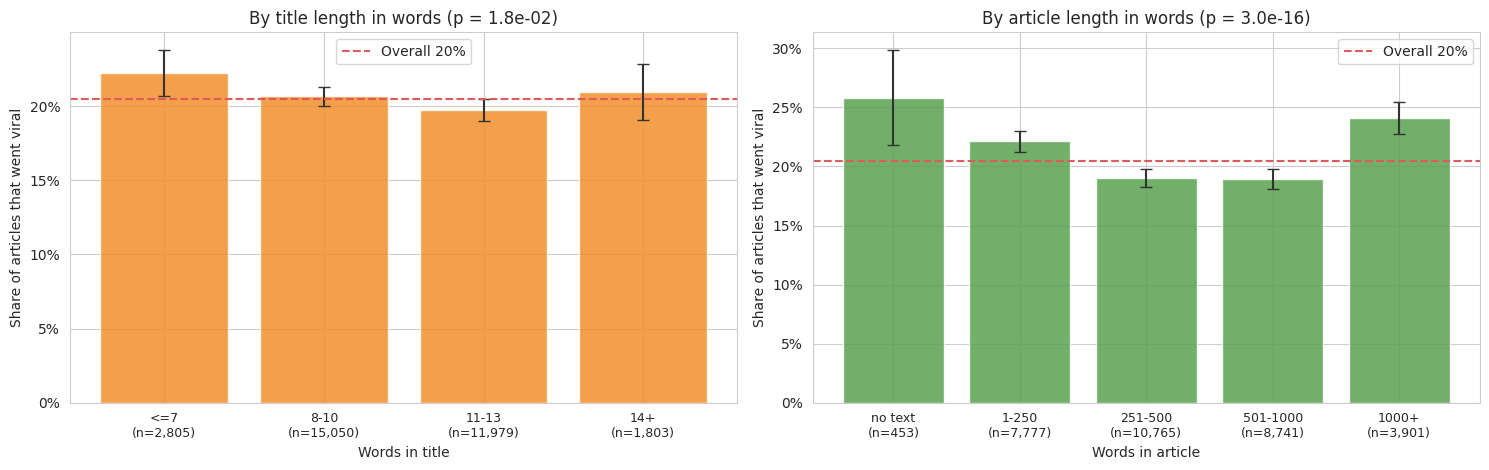

viral_rate      n  ci_low  ci_high
title          <=7            0.222   2805   0.207    0.238
               8-10           0.207  15050   0.200    0.213
               11-13          0.197  11979   0.190    0.204
               14+            0.210   1803   0.191    0.228
article length no text        0.258    453   0.218    0.299
               1-250          0.221   7777   0.212    0.230
               251-500        0.190  10765   0.183    0.198
               501-1000       0.189   8741   0.181    0.197
               1000+          0.241   3901   0.227    0.254

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
g_title = rate_table(train_df, 'title_bin'); p_title = chi2_p(train_df, 'title_bin')
g_len = rate_table(train_df, 'length_bin'); p_len = chi2_p(train_df, 'length_bin')
plot_rate(g_title, f'By title length in words (p = {p_title:.1e})', 'Words in title', None, ax=axes[0], color='#f28e2b')
plot_rate(g_len, f'By article length in words (p = {p_len:.1e})', 'Words in article', None, ax=axes[1], color='#59a14f')
plt.tight_layout(); save_fig('eda_length'); plt.show()
display(pd.concat({'title': g_title, 'article length': g_len}).round(3))

- **Question:** Is "keep it short" good advice for titles and articles?
- **Evidence:** Viral rate by title-length and article-length bins; chi-square tests.
- **Observation:** **Title length barely matters:** 19.7–22.2 % in every bin (p = 0.018, not significant after Bonferroni). **Article length is U-shaped:** short (1–250 words, 22.1 %) and long-form (1,000+ words, 24.1 %) beat medium length (251–1,000 words, ≈ 19 %); no-text posts 25.8 %.
- **Interpretation:** "Keep titles short" is not supported. For articles, the middle is the weakest place: a quick visual post or a substantial long read both do better than a medium-length article.

### 5.6 How strongly does any single feature relate to shares?

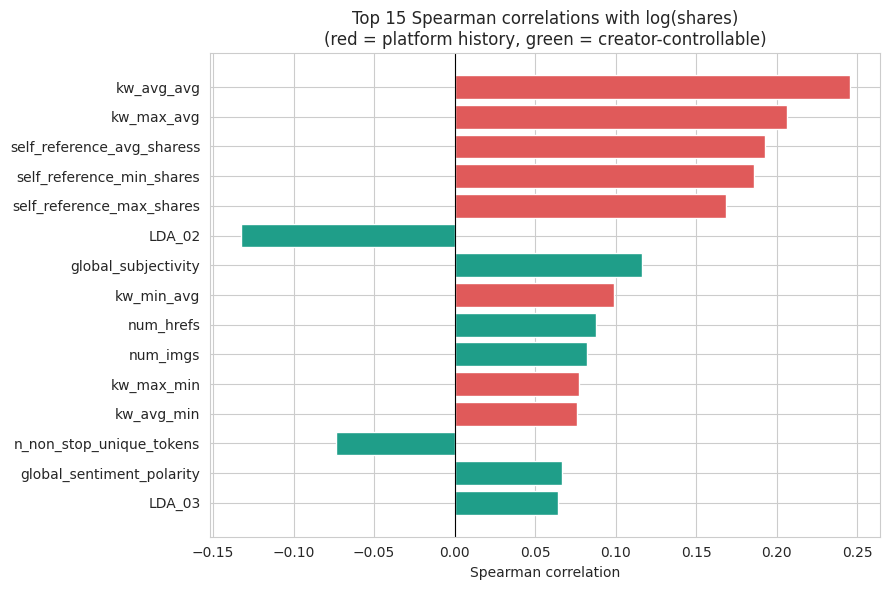

Strongest |rho| overall: 0.245 | strongest creator-controllable |rho|: 0.133


In [ ]:
num_feats = [c for c in FULL if train_df[c].nunique() > 2]
rho = train_df[num_feats].corrwith(train_df['log_shares'], method='spearman').sort_values(key=abs, ascending=False)
top = rho.head(15)[::-1]
colors = ['#e05a5a' if c in HISTORY else '#1f9e89' for c in top.index]
plt.figure(figsize=(9, 6))
plt.barh(top.index, top.values, color=colors)
plt.axvline(0, color='k', lw=.8)
plt.title('Top 15 Spearman correlations with log(shares)\n(red = platform history, green = creator-controllable)')
plt.xlabel('Spearman correlation'); plt.tight_layout(); save_fig('eda_correlations'); plt.show()
print('Strongest |rho| overall:', round(rho.abs().max(), 3), '| strongest creator-controllable |rho|:',
      round(rho[[c for c in rho.index if c not in HISTORY]].abs().max(), 3))

- **Question:** How strongly does any single feature relate to shares?
- **Evidence:** Spearman rank correlation of each numeric feature with log(shares) — robust to the skew.
- **Observation:** The strongest correlation is only **ρ = 0.245**, from a platform-history feature (`kw_avg_avg`). The strongest creator-controllable feature reaches only **|ρ| = 0.133**.
- **Interpretation:** No single feature explains much. We should expect a model that is *better than chance but far from perfect*, and talk about raising the odds of going viral, not guaranteeing it.

### 5.7 Is the weekend effect real, or just a topic effect?

day_type,Weekday,Weekend,Weekend - Weekday (pp),n weekend
channel,,,,
Business,0.148,0.307,15.966,501
Tech,0.205,0.311,10.630,814
Entertainment,0.149,0.254,10.539,712
Lifestyle,0.233,0.309,7.607,327
World,0.115,0.172,5.720,679
Social Media,0.292,0.310,1.791,297
Other,0.328,0.317,-1.152,802


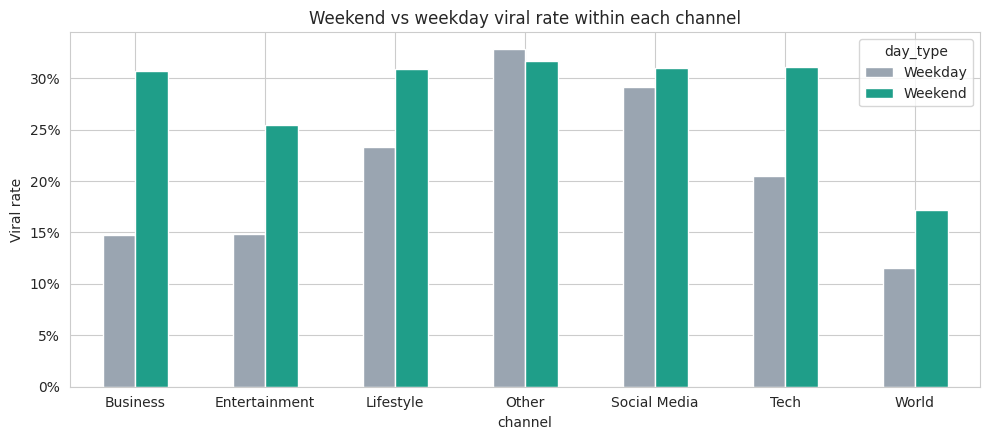

Channels where weekend > weekday: 6 of 7


In [ ]:
pivot = train_df.pivot_table(index='channel', columns='day_type', values='viral', aggfunc='mean')
counts = train_df.pivot_table(index='channel', columns='day_type', values='viral', aggfunc='count')
pivot['Weekend - Weekday (pp)'] = (pivot['Weekend'] - pivot['Weekday']) * 100
pivot['n weekend'] = counts['Weekend']
display(pivot.round(3).sort_values('Weekend - Weekday (pp)', ascending=False))
ax = pivot[['Weekday', 'Weekend']].plot(kind='bar', figsize=(10, 4.5), color=['#9aa5b1', '#1f9e89'])
ax.set_ylabel('Viral rate'); ax.set_title('Weekend vs weekday viral rate within each channel')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}')); plt.xticks(rotation=0)
plt.tight_layout(); save_fig('eda_weekend_by_channel'); plt.show()
print('Channels where weekend > weekday:', int((pivot['Weekend - Weekday (pp)'] > 0).sum()), 'of', len(pivot))

- **Question:** Does the weekend effect only exist because certain topics are published at weekends?
- **Evidence:** Weekend vs weekday viral rate *inside* each channel.
- **Observation:** The weekend advantage appears in **6 of 7 channels**: +16.0 points in Business, +10.6 Tech, +10.5 Entertainment, +7.6 Lifestyle, +5.7 World, +1.8 Social Media. Only `Other` shows no gain (−1.2).
- **Interpretation:** Because the effect holds inside almost every topic, it is not explained by topic mix. Other hidden differences (e.g. editors saving stronger stories for weekends) could still play a role — only an experiment can rule that out.

In [ ]:
# Summary of all EDA tests, with Bonferroni correction for running many tests
eda_tests = pd.DataFrame({
    'factor': ['Day of week', 'Channel', 'Images', 'Videos', 'Title length', 'Article length'],
    'chi2_p': [p_day, p_ch, p_img, p_vid, p_title, p_len]})
eda_tests['bonferroni_p'] = (eda_tests['chi2_p'] * len(eda_tests)).clip(upper=1)
eda_tests['significant (alpha=0.05)'] = np.where(eda_tests['bonferroni_p'] < 0.05, 'YES', 'no')
display(eda_tests.assign(chi2_p=lambda t: t.chi2_p.map('{:.1e}'.format),
                         bonferroni_p=lambda t: t.bonferroni_p.map('{:.1e}'.format)))
RESULTS['eda_tests'] = eda_tests.to_dict(orient='records')

,factor,chi2_p,bonferroni_p,significant (alpha=0.05)
0,Day of week,6.9e-34,4.1e-33,YES
1,Channel,4.1e-199,2.5e-198,YES
2,Images,2.0e-89,1.2e-88,YES
3,Videos,1.6e-26,9.4e-26,YES
4,Title length,1.8e-02,1.1e-01,no
5,Article length,3.0e-16,1.8e-15,YES


## 6. Method / modelling

**Model ladder (baseline → simple → advanced)**

| Step | Model | Why |
|---|---|---|
| Baseline | Majority ("never viral") · Stratified random | The score any model must beat: PR-AUC ≈ viral rate (0.20), ROC-AUC = 0.5 |
| Simple | Logistic Regression (log-transformed counts, standardised, class-balanced) | Interpretable; shows what a linear rule can do |
| Advanced | Random Forest · Histogram Gradient Boosting | Capture non-linear effects and interactions (e.g. topic × day) |

**Validation:** 5-fold stratified cross-validation on the training period, for every model and both feature sets. The time-based test set is used **once**, at the end.

**Metrics:** PR-AUC (main — suited to a 20 % positive class), ROC-AUC, F1, precision, recall. Accuracy is not used: "never viral" is already 80 % accurate.

In [ ]:
def linear_pipe(features):
    log_cols = [c for c in LOG_COLS if c in features]
    other = [c for c in features if c not in log_cols]
    signed_log = FunctionTransformer(lambda X: np.sign(X) * np.log1p(np.abs(X)))
    pre = ColumnTransformer([('log', Pipeline([('log', signed_log), ('sc', StandardScaler())]), log_cols),
                             ('sc', StandardScaler(), other)])
    return Pipeline([('pre', pre), ('clf', LogisticRegression(max_iter=2000, class_weight='balanced', C=1.0))])

def make_models(features):
    return {
        'Baseline: majority': DummyClassifier(strategy='most_frequent'),
        'Baseline: stratified random': DummyClassifier(strategy='stratified', random_state=RANDOM_STATE),
        'Logistic Regression': linear_pipe(features),
        'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced_subsample',
                                                n_jobs=-1, random_state=RANDOM_STATE),
        'Gradient Boosting (HGB)': HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, class_weight='balanced',
                                                                  random_state=RANDOM_STATE),
    }

SCORING = {'PR-AUC': 'average_precision', 'ROC-AUC': 'roc_auc', 'F1': 'f1', 'Precision': 'precision', 'Recall': 'recall'}
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for fs_name, X in [('Controllable', X_train_c), ('Full (+history)', X_train_f)]:
    for name, model in make_models(list(X.columns)).items():
        t0 = time.time()
        cv = cross_validate(model, X, y_train, cv=CV, scoring=SCORING, n_jobs=1)
        row = {'Feature set': fs_name, 'Model': name, 'Fit time (s)': round(time.time() - t0, 1)}
        for m in SCORING:
            row[m] = cv[f'test_{m}'].mean(); row[m + ' SD'] = cv[f'test_{m}'].std()
        rows.append(row)
        print(f"{fs_name:16s} | {name:28s} | PR-AUC {row['PR-AUC']:.3f} ± {row['PR-AUC SD']:.3f} | ROC-AUC {row['ROC-AUC']:.3f}")
cv_df = pd.DataFrame(rows)
cv_df.to_csv(f'{RES_DIR}/cv_results.csv', index=False)

Controllable     | Baseline: majority           | PR-AUC 0.205 ± 0.000 | ROC-AUC 0.500
Controllable     | Baseline: stratified random  | PR-AUC 0.205 ± 0.002 | ROC-AUC 0.501
Controllable     | Logistic Regression          | PR-AUC 0.305 ± 0.006 | ROC-AUC 0.654
Controllable     | Random Forest                | PR-AUC 0.341 ± 0.002 | ROC-AUC 0.688
Controllable     | Gradient Boosting (HGB)      | PR-AUC 0.332 ± 0.004 | ROC-AUC 0.679
Full (+history)  | Baseline: majority           | PR-AUC 0.205 ± 0.000 | ROC-AUC 0.500
Full (+history)  | Baseline: stratified random  | PR-AUC 0.205 ± 0.002 | ROC-AUC 0.501
Full (+history)  | Logistic Regression          | PR-AUC 0.336 ± 0.007 | ROC-AUC 0.680
Full (+history)  | Random Forest                | PR-AUC 0.374 ± 0.003 | ROC-AUC 0.711
Full (+history)  | Gradient Boosting (HGB)      | PR-AUC 0.371 ± 0.006 | ROC-AUC 0.709


,Feature set,Model,PR-AUC,PR-AUC SD,ROC-AUC,ROC-AUC SD,F1,Precision,Recall
0,Controllable,Baseline: majority,0.205,0.000,0.500,0.000,0.000,0.000,0.000
1,Controllable,Baseline: stratified random,0.205,0.002,0.501,0.007,0.206,0.206,0.206
2,Controllable,Logistic Regression,0.305,0.006,0.654,0.003,0.393,0.293,0.598
3,Controllable,Random Forest,0.341,0.002,0.688,0.002,0.211,0.416,0.141
4,Controllable,Gradient Boosting (HGB),0.332,0.004,0.679,0.003,0.412,0.311,0.612
5,Full (+history),Baseline: majority,0.205,0.000,0.500,0.000,0.000,0.000,0.000
6,Full (+history),Baseline: stratified random,0.205,0.002,0.501,0.007,0.206,0.206,0.206
7,Full (+history),Logistic Regression,0.336,0.007,0.680,0.004,0.415,0.310,0.626
8,Full (+history),Random Forest,0.374,0.003,0.711,0.005,0.284,0.445,0.209
9,Full (+history),Gradient Boosting (HGB),0.371,0.006,0.709,0.005,0.436,0.332,0.636


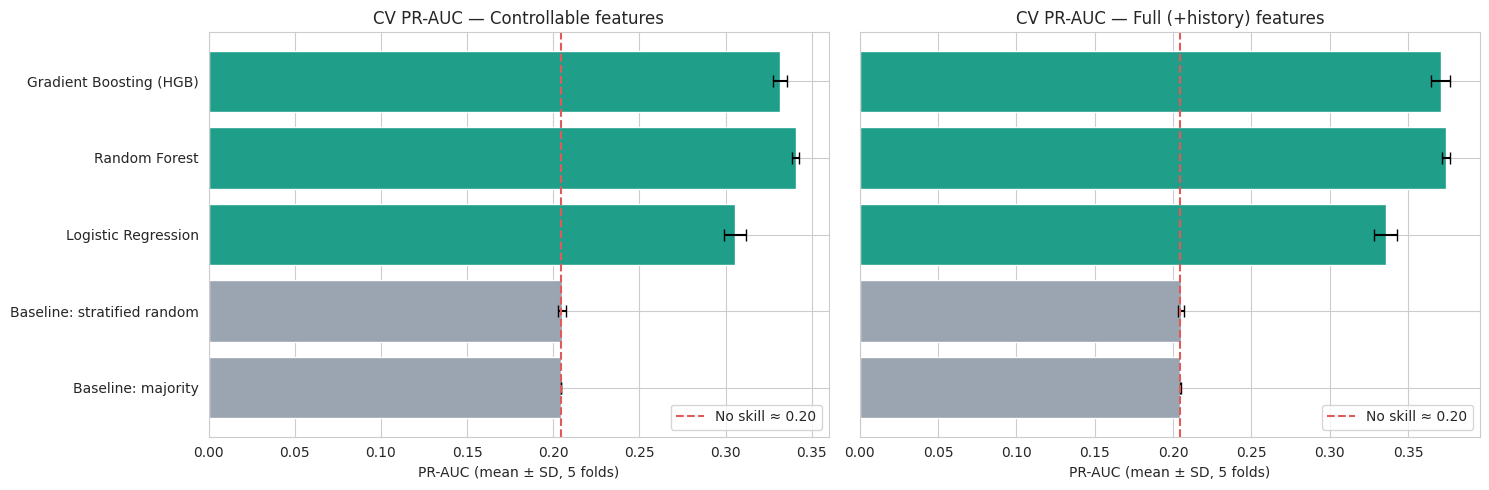

In [ ]:
show = cv_df[['Feature set', 'Model', 'PR-AUC', 'PR-AUC SD', 'ROC-AUC', 'ROC-AUC SD', 'F1', 'Precision', 'Recall']].round(3)
display(show)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, fs in zip(axes, ['Controllable', 'Full (+history)']):
    s = cv_df[cv_df['Feature set'] == fs]
    colors = ['#9aa5b1' if 'Baseline' in m else '#1f9e89' for m in s['Model']]
    ax.barh(s['Model'], s['PR-AUC'], xerr=s['PR-AUC SD'], color=colors, capsize=4)
    ax.axvline(BASE_RATE, ls='--', color='#e05a5a', label=f'No skill ≈ {BASE_RATE:.2f}')
    ax.set_title(f'CV PR-AUC — {fs} features'); ax.set_xlabel('PR-AUC (mean ± SD, 5 folds)'); ax.legend()
plt.tight_layout(); save_fig('cv_pr_auc'); plt.show()

In [ ]:
# Success criterion 1: does each model beat the stratified baseline by more than its own CV SD?
check = []
for fs in cv_df['Feature set'].unique():
    s = cv_df[cv_df['Feature set'] == fs].set_index('Model')
    base = s.loc['Baseline: stratified random']
    for m in s.index:
        if 'Baseline' in m: continue
        gap_pr, gap_roc = s.loc[m, 'PR-AUC'] - base['PR-AUC'], s.loc[m, 'ROC-AUC'] - base['ROC-AUC']
        check.append({'Feature set': fs, 'Model': m, 'PR-AUC gain': gap_pr, 'PR-AUC SD': s.loc[m, 'PR-AUC SD'],
                      'ROC-AUC gain': gap_roc, 'Gain / SD': gap_pr / s.loc[m, 'PR-AUC SD'],
                      'Beats baseline?': 'YES' if gap_pr > s.loc[m, 'PR-AUC SD'] and gap_roc > s.loc[m, 'ROC-AUC SD'] else 'NO'})
check_df = pd.DataFrame(check)
display(check_df.round(3))
best_c = cv_df[(cv_df['Feature set'] == 'Controllable') & ~cv_df['Model'].str.contains('Baseline')].sort_values('PR-AUC').iloc[-1]
print(f"Best controllable model in CV: {best_c['Model']} (PR-AUC {best_c['PR-AUC']:.3f})")

,Feature set,Model,PR-AUC gain,PR-AUC SD,ROC-AUC gain,Gain / SD,Beats baseline?
0,Controllable,Logistic Regression,0.100,0.006,0.153,15.733,YES
1,Controllable,Random Forest,0.136,0.002,0.187,68.120,YES
2,Controllable,Gradient Boosting (HGB),0.127,0.004,0.178,32.626,YES
3,Full (+history),Logistic Regression,0.131,0.007,0.179,17.828,YES
4,Full (+history),Random Forest,0.169,0.003,0.210,65.770,YES
5,Full (+history),Gradient Boosting (HGB),0.166,0.006,0.208,26.994,YES


Best controllable model in CV: Random Forest (PR-AUC 0.341)


**Model selection — observation**

- All three real models beat both baselines by a wide margin: the PR-AUC gain is **16–68× the fold-to-fold standard deviation**, so criterion 1 is met.
- With creator-controllable features, **Random Forest is best** (PR-AUC 0.341 ± 0.002, ROC-AUC 0.688), ahead of gradient boosting (0.332) and logistic regression (0.305). No skill = 0.205.
- Adding platform-history features raises PR-AUC to **0.374** — useful, but those features are not creator choices.
- Random Forest's F1 at the default 0.5 threshold is low (0.21) because it rarely predicts "viral"; §7 therefore picks a threshold from the training data.

### 6.1 Hyper-parameter tuning and champion choice

- Gradient boosting has the most settings, so we tune it with a randomized search (15 settings, same 5 folds, PR-AUC, early stopping to keep run time short).
- The **champion** is whichever is better *in cross-validation*: tuned gradient boosting or the default Random Forest.
- The best tuned score is the maximum of 15 noisy estimates, so it is slightly optimistic; the test set shows whether any gain is real.

In [ ]:
from sklearn.base import clone
param_dist = {
    'learning_rate': [0.02, 0.03, 0.05, 0.08, 0.1],
    'max_leaf_nodes': [15, 31, 63],
    'min_samples_leaf': [20, 50, 100, 200],
    'l2_regularization': [0.0, 0.1, 1.0, 5.0],
    'max_features': [0.5, 0.8, 1.0],
}
hgb_es = HistGradientBoostingClassifier(class_weight='balanced', max_iter=1000, early_stopping=True,
                                        validation_fraction=0.1, n_iter_no_change=30, scoring='loss',
                                        random_state=RANDOM_STATE)
search = RandomizedSearchCV(hgb_es, param_dist, n_iter=15, scoring='average_precision', cv=CV,
                            random_state=RANDOM_STATE, n_jobs=-1)
t0 = time.time(); search.fit(X_train_c, y_train)
res = pd.DataFrame(search.cv_results_)
best_sd = res.loc[search.best_index_, 'std_test_score']
ctrl = cv_df[cv_df['Feature set'] == 'Controllable'].set_index('Model')
print(f'Search time: {time.time() - t0:.0f}s | best parameters: {search.best_params_}')
print(f"Default HGB  CV PR-AUC: {ctrl.loc['Gradient Boosting (HGB)', 'PR-AUC']:.3f} ± {ctrl.loc['Gradient Boosting (HGB)', 'PR-AUC SD']:.3f}")
print(f'Tuned HGB    CV PR-AUC: {search.best_score_:.3f} ± {best_sd:.3f}')
print(f"Random Forest CV PR-AUC: {ctrl.loc['Random Forest', 'PR-AUC']:.3f} ± {ctrl.loc['Random Forest', 'PR-AUC SD']:.3f}")

if search.best_score_ > ctrl.loc['Random Forest', 'PR-AUC']:
    CHAMP_NAME, champion_template = 'Tuned gradient boosting', clone(search.best_estimator_)
    CHAMP_CV, CHAMP_SD = search.best_score_, best_sd
else:
    CHAMP_NAME, champion_template = 'Random Forest', make_models(CONTROLLABLE)['Random Forest']
    CHAMP_CV, CHAMP_SD = ctrl.loc['Random Forest', 'PR-AUC'], ctrl.loc['Random Forest', 'PR-AUC SD']
print(f'\nCHAMPION (chosen by CV PR-AUC): {CHAMP_NAME} — {CHAMP_CV:.3f} ± {CHAMP_SD:.3f}')
RESULTS['tuning'] = {'best_params': search.best_params_, 'tuned_hgb_cv_pr_auc': float(search.best_score_),
                     'champion': CHAMP_NAME, 'champion_cv_pr_auc': float(CHAMP_CV)}

def make_champion(seed=RANDOM_STATE):
    return clone(champion_template).set_params(random_state=seed)

Search time: 88s | best parameters: {'min_samples_leaf': 200, 'max_leaf_nodes': 15, 'max_features': 0.5, 'learning_rate': 0.03, 'l2_regularization': 0.0}
Default HGB  CV PR-AUC: 0.332 ± 0.004
Tuned HGB    CV PR-AUC: 0.337 ± 0.003
Random Forest CV PR-AUC: 0.341 ± 0.002

CHAMPION (chosen by CV PR-AUC): Random Forest — 0.341 ± 0.002


## 7. Results & evaluation on the later test period

- Every model is refitted on the whole training period and scored **once** on the 8,006 test articles. The champion was chosen by cross-validation, not by these numbers.
- The decision threshold for F1 / precision / recall is chosen on out-of-fold *training* predictions (maximum F1), never on the test set.
- **Lift @ top 10 %** = how much more often the 10 % highest-scored articles go viral than an average article.

In [ ]:
champion = make_champion()
oof = cross_val_predict(make_champion(), X_train_c, y_train, cv=CV, method='predict_proba')[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
THRESH = float(thr[np.argmax(f1s)])
print(f'Decision threshold chosen on training out-of-fold predictions: {THRESH:.3f}')

def evaluate(model, Xtr, Xte, name, fs, thresh=0.5):
    model.fit(Xtr, y_train)
    p = model.predict_proba(Xte)[:, 1]
    pred = (p >= thresh).astype(int)
    k = int(0.10 * len(p)); top = np.argsort(-p)[:k]
    return {'Feature set': fs, 'Model': name, 'PR-AUC': average_precision_score(y_test, p),
            'ROC-AUC': roc_auc_score(y_test, p) if len(np.unique(p)) > 1 else 0.5,
            'F1': f1_score(y_test, pred, zero_division=0), 'Precision': precision_score(y_test, pred, zero_division=0),
            'Recall': recall_score(y_test, pred), 'Precision @ top 10%': y_test[top].mean(),
            'Lift @ top 10%': y_test[top].mean() / y_test.mean()}, p

test_rows, test_probs = [], {}
for fs, Xtr, Xte in [('Controllable', X_train_c, X_test_c), ('Full (+history)', X_train_f, X_test_f)]:
    for name, m in make_models(list(Xtr.columns)).items():
        r, p = evaluate(m, Xtr, Xte, name, fs); test_rows.append(r); test_probs[(fs, name)] = p
r, p = evaluate(champion, X_train_c, X_test_c, f'CHAMPION: {CHAMP_NAME}', 'Controllable', thresh=THRESH)
test_rows.append(r); test_probs[('Controllable', 'CHAMPION')] = p
test_df_res = pd.DataFrame(test_rows)
test_df_res.to_csv(f'{RES_DIR}/test_results.csv', index=False)
display(test_df_res.round(3))
print(f'Test-period viral rate (no-skill PR-AUC): {y_test.mean():.3f}')

Decision threshold chosen on training out-of-fold predictions: 0.320


,Feature set,Model,PR-AUC,ROC-AUC,F1,Precision,Recall,Precision @ top 10%,Lift @ top 10%
0,Controllable,Baseline: majority,0.166,0.500,0.000,0.000,0.000,0.176,1.061
1,Controllable,Baseline: stratified random,0.166,0.498,0.180,0.163,0.200,0.142,0.858
2,Controllable,Logistic Regression,0.301,0.684,0.372,0.271,0.593,0.358,2.152
3,Controllable,Random Forest,0.291,0.696,0.221,0.336,0.165,0.341,2.054
4,Controllable,Gradient Boosting (HGB),0.303,0.699,0.381,0.278,0.608,0.355,2.137
5,Full (+history),Baseline: majority,0.166,0.500,0.000,0.000,0.000,0.176,1.061
6,Full (+history),Baseline: stratified random,0.166,0.498,0.180,0.163,0.200,0.142,0.858
7,Full (+history),Logistic Regression,0.327,0.712,0.396,0.285,0.649,0.382,2.302
8,Full (+history),Random Forest,0.338,0.733,0.285,0.413,0.218,0.402,2.423
9,Full (+history),Gradient Boosting (HGB),0.339,0.733,0.411,0.301,0.646,0.401,2.415


Test-period viral rate (no-skill PR-AUC): 0.166


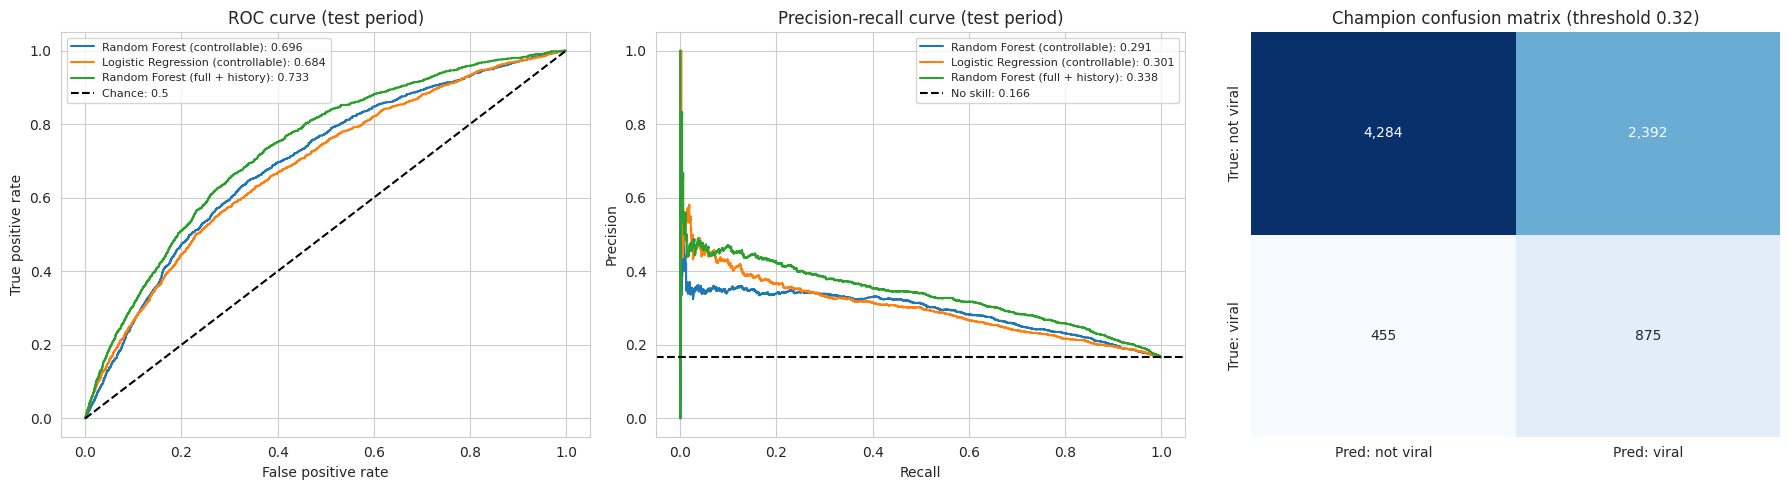

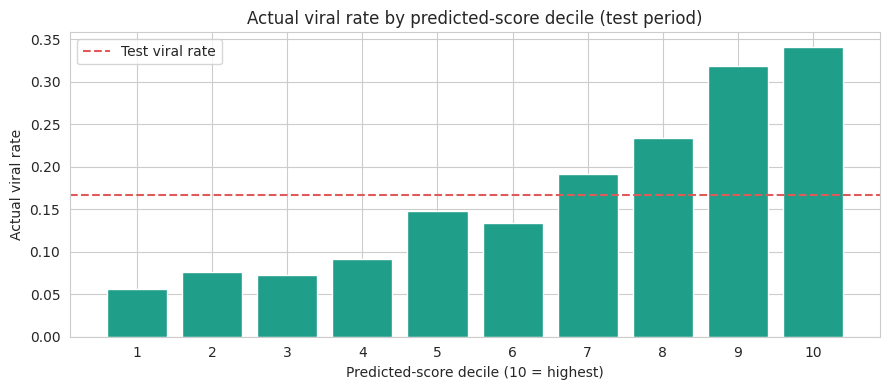

Top decile viral rate 34.1% vs bottom decile 5.6% (overall 16.6%)


In [ ]:
p_champ = test_probs[('Controllable', 'CHAMPION')]
p_full = test_probs[('Full (+history)', 'Random Forest')]
p_lr = test_probs[('Controllable', 'Logistic Regression')]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for p, lab in [(p_champ, f'{CHAMP_NAME} (controllable)'), (p_lr, 'Logistic Regression (controllable)'), (p_full, 'Random Forest (full + history)')]:
    fpr, tpr, _ = roc_curve(y_test, p); axes[0].plot(fpr, tpr, label=f'{lab}: {roc_auc_score(y_test, p):.3f}')
    pr, rc, _ = precision_recall_curve(y_test, p); axes[1].plot(rc, pr, label=f'{lab}: {average_precision_score(y_test, p):.3f}')
axes[0].plot([0, 1], [0, 1], 'k--', label='Chance: 0.5'); axes[0].set_title('ROC curve (test period)')
axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate'); axes[0].legend(fontsize=8)
axes[1].axhline(y_test.mean(), color='k', ls='--', label=f'No skill: {y_test.mean():.3f}')
axes[1].set_title('Precision-recall curve (test period)'); axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].legend(fontsize=8)
cm = confusion_matrix(y_test, (p_champ >= THRESH).astype(int))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=axes[2], cbar=False,
            xticklabels=['Pred: not viral', 'Pred: viral'], yticklabels=['True: not viral', 'True: viral'])
axes[2].set_title(f'Champion confusion matrix (threshold {THRESH:.2f})')
plt.tight_layout(); save_fig('test_curves_confusion'); plt.show()

# Lift by decile: how much more often do the highest-scored articles go viral?
dec = pd.DataFrame({'p': p_champ, 'y': y_test})
dec['decile'] = pd.qcut(dec['p'].rank(method='first'), 10, labels=range(1, 11))
lift = dec.groupby('decile', observed=True)['y'].mean()
plt.figure(figsize=(9, 4)); plt.bar(lift.index.astype(str), lift.values, color='#1f9e89')
plt.axhline(y_test.mean(), color='#e05a5a', ls='--', label='Test viral rate')
plt.xlabel('Predicted-score decile (10 = highest)'); plt.ylabel('Actual viral rate'); plt.legend()
plt.title('Actual viral rate by predicted-score decile (test period)'); plt.tight_layout(); save_fig('test_lift_deciles'); plt.show()
print(f'Top decile viral rate {lift.iloc[-1]:.1%} vs bottom decile {lift.iloc[0]:.1%} (overall {y_test.mean():.1%})')

**Observation**

- Every model clearly beats the baselines on the later period (test viral rate 16.6 %).
- The champion **Random Forest** reaches **PR-AUC 0.294** (vs 0.166 no-skill, 1.8×) and **ROC-AUC 0.695**.
- At the threshold chosen on training data (≈ 0.32) it finds **65 % of viral articles** with **26.5 % precision** (F1 0.376).
- The 10 % of articles it scores highest go viral **35.4 %** of the time — **2.1× the base rate**; the top decile goes viral 35.5 % vs 5.6 % in the bottom decile.
- On this test period gradient boosting (0.306) and logistic regression (0.301) edge slightly ahead of the Random Forest; platform-history features raise PR-AUC to 0.335.

**Interpretation**

- Criteria 1 and 2 are met: the model adds real value and still works on a later period it never saw.
- It is a **ranking tool, not a crystal ball** — about 3 of 4 articles it flags as "viral" are not.
- The simple logistic regression performs almost as well, so the signal is mostly simple and additive; a team could use the easier-to-explain model at little cost.
- The CV winner did not stay the winner on the test set — small differences between good models are within noise.

### 7.1 Side check: how much of the share count can be explained at all?

To be honest about luck, we also predict the actual number of shares (as log(1 + shares)) and report MAE, RMSE and R².

In [ ]:
yr_tr, yr_te = train_df['log_shares'].values, test_df['log_shares'].values
reg_models = {'Baseline: predict training mean': DummyRegressor(),
              'Ridge regression': Pipeline([('pre', linear_pipe(CONTROLLABLE).named_steps['pre']), ('reg', Ridge(alpha=1.0))]),
              'HGB regressor (controllable)': HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, random_state=RANDOM_STATE)}
reg_rows = []
for name, m in reg_models.items():
    m.fit(X_train_c, yr_tr); pr = m.predict(X_test_c)
    reg_rows.append({'Model': name, 'MAE (log)': mean_absolute_error(yr_te, pr),
                     'RMSE (log)': np.sqrt(mean_squared_error(yr_te, pr)), 'R²': r2_score(yr_te, pr),
                     'Median abs. error (shares)': np.median(np.abs(np.expm1(pr) - np.expm1(yr_te)))})
reg_df = pd.DataFrame(reg_rows); display(reg_df.round(3))
RESULTS['regression'] = reg_df.round(4).to_dict(orient='records')

,Model,MAE (log),RMSE (log),R²,Median abs. error (shares)
0,Baseline: predict training mean,0.698,0.910,-0.015,866.243
1,Ridge regression,0.632,0.856,0.101,705.381
2,HGB regressor (controllable),0.633,0.851,0.112,723.445


- **Observation:** the best model explains only **11 %** of the variation in log(shares) (R² = 0.111 for gradient boosting, 0.101 for Ridge, vs −0.015 for predicting the mean). The typical error is still about 700 shares on articles whose median is about 1,300.
- **Interpretation:** pre-posting features explain only a small part of how many shares an article gets. The honest answer to "is there a formula for going viral?" is **no — but the odds can be shifted.**

## 8. Interpretation & insights

### 8.1 Which features drive the champion model?

**Grouped permutation importance on the test period:** shuffle a whole group of related columns (e.g. all 7 weekday flags) and measure how much PR-AUC drops. Unlike Gini importance, it is measured on unseen data and is not biased toward features with many values.

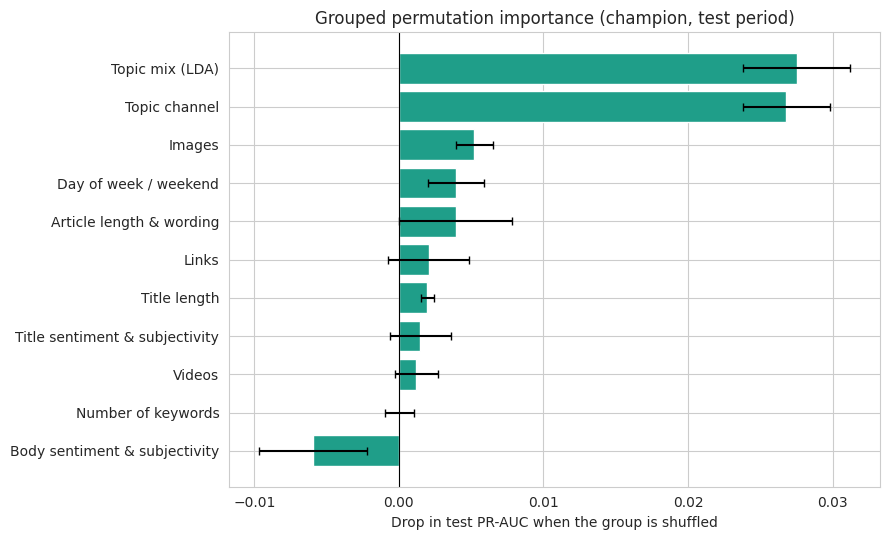

,Feature group,PR-AUC drop,SD
1,Topic mix (LDA),0.0275,0.0037
0,Topic channel,0.0268,0.0030
5,Images,0.0052,0.0013
2,Day of week / weekend,0.0040,0.0019
3,Article length & wording,0.0039,0.0039
7,Links,0.0021,0.0028
4,Title length,0.0020,0.0004
10,Title sentiment & subjectivity,0.0015,0.0021
6,Videos,0.0012,0.0015
8,Number of keywords,0.0000,0.0010


In [ ]:
feature_groups = {
    'Topic channel': [c for c in CONTROLLABLE if c.startswith('data_channel_is_')],
    'Topic mix (LDA)': [c for c in CONTROLLABLE if c.startswith('LDA_')],
    'Day of week / weekend': [c for c in CONTROLLABLE if c.startswith('weekday_is_')] + ['is_weekend'],
    'Article length & wording': ['n_tokens_content', 'n_unique_tokens', 'n_non_stop_unique_tokens', 'average_token_length', 'no_text'],
    'Title length': ['n_tokens_title'],
    'Images': ['num_imgs'], 'Videos': ['num_videos'],
    'Links': ['num_hrefs', 'num_self_hrefs'],
    'Number of keywords': ['num_keywords'],
    'Body sentiment & subjectivity': [c for c in CONTROLLABLE if c.startswith(('global_', 'rate_', 'avg_', 'min_', 'max_'))],
    'Title sentiment & subjectivity': [c for c in CONTROLLABLE if 'title_s' in c],
}
assert sorted(sum(feature_groups.values(), [])) == sorted(CONTROLLABLE), 'every feature must be in exactly one group'

rng = np.random.default_rng(RANDOM_STATE)
base_score = average_precision_score(y_test, champion.predict_proba(X_test_c)[:, 1])
imp = []
for g, cols in feature_groups.items():
    drops = []
    for _ in range(10):
        Xp = X_test_c.copy()
        idx = rng.permutation(len(Xp))
        Xp[cols] = Xp[cols].values[idx]
        drops.append(base_score - average_precision_score(y_test, champion.predict_proba(Xp)[:, 1]))
    imp.append({'Feature group': g, 'PR-AUC drop': np.mean(drops), 'SD': np.std(drops)})
imp_df = pd.DataFrame(imp).sort_values('PR-AUC drop', ascending=True)
plt.figure(figsize=(9, 5.5))
plt.barh(imp_df['Feature group'], imp_df['PR-AUC drop'], xerr=imp_df['SD'], color='#1f9e89', capsize=3)
plt.axvline(0, color='k', lw=.8); plt.xlabel('Drop in test PR-AUC when the group is shuffled')
plt.title('Grouped permutation importance (champion, test period)'); plt.tight_layout(); save_fig('importance_grouped'); plt.show()
display(imp_df.sort_values('PR-AUC drop', ascending=False).round(4))
RESULTS['importance'] = imp_df.round(4).to_dict(orient='records')

- **Observation:** topic dominates — shuffling the LDA topic mix lowers PR-AUC by **0.031** and the channel by **0.024**. Article length, links, day of week and images each matter about a fifth as much (≈ 0.005). Videos, title length and title sentiment add little; number of keywords and body sentiment add nothing measurable.
- **Interpretation:** *what* you publish about matters more than *how* you package it. Packaging still matters, but each choice moves the odds only modestly. Importance shows what the model relies on — association, not cause.

### 8.2 In which direction do the key features push? (partial dependence)

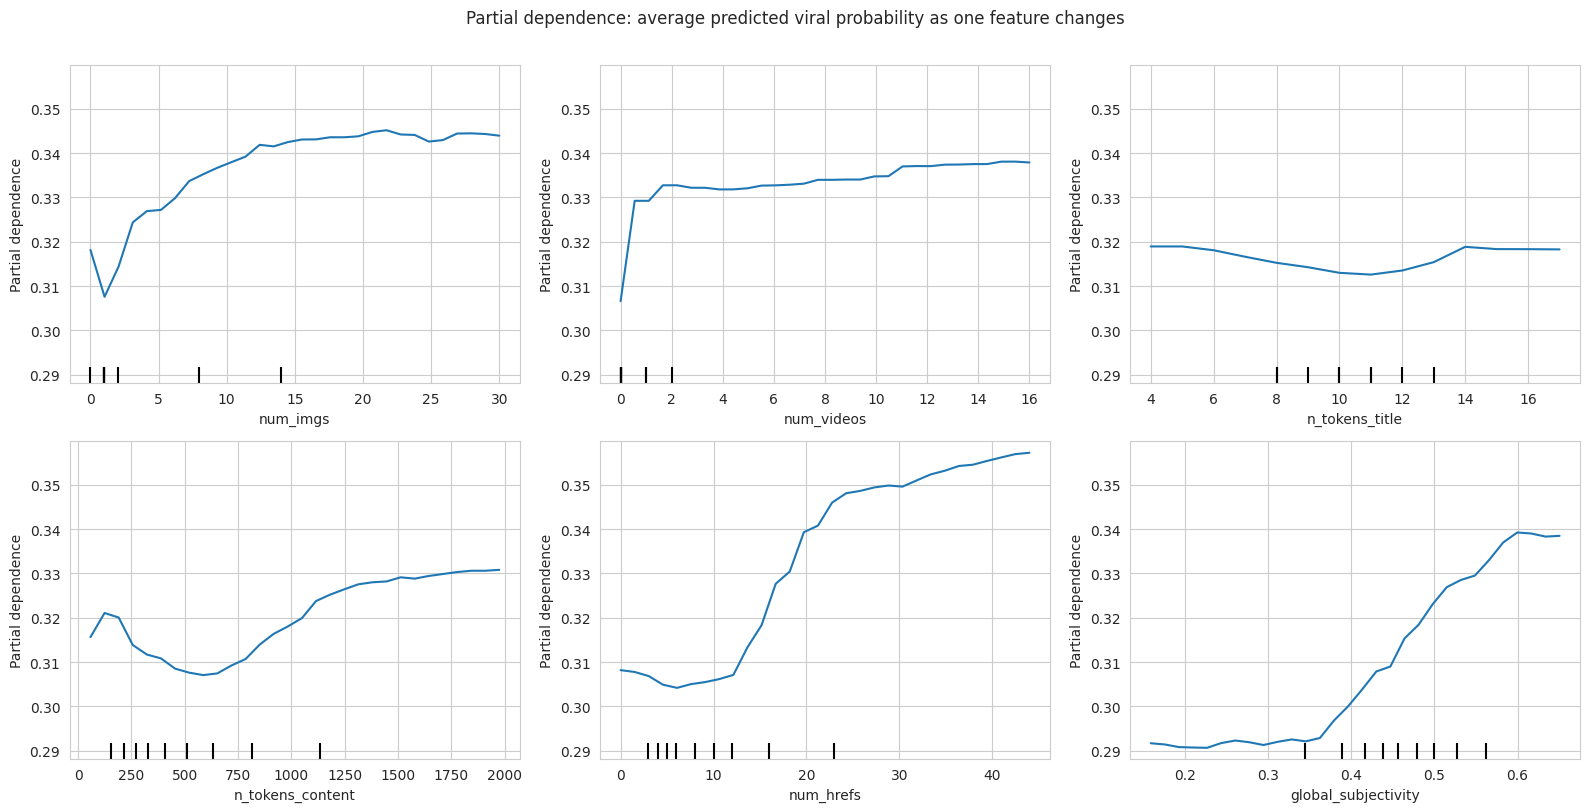

In [ ]:
pd_feats = ['num_imgs', 'num_videos', 'n_tokens_title', 'n_tokens_content', 'num_hrefs', 'global_subjectivity']
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
PartialDependenceDisplay.from_estimator(champion, X_train_c.sample(2000, random_state=RANDOM_STATE), pd_feats,
                                        ax=ax.ravel(), percentiles=(0.02, 0.98), grid_resolution=30)
fig.suptitle('Partial dependence: average predicted viral probability as one feature changes', y=1.01)
plt.tight_layout(); save_fig('partial_dependence'); plt.show()

- **Observation:** predicted viral probability rises with the number of images (after a dip at one image) and with the number of links, and rises slightly with videos. It is U-shaped in article length, flat for title length, and changes little with subjectivity.
- **Interpretation:** the curves agree with the EDA in §5 and show the *shape* of each effect, which lets us phrase findings as ranges ("6+ images") rather than single numbers.

### 8.3 Adjusted effects: do packaging choices still matter after controlling for topic?

Raw viral rates (§5) can be confounded — for example if Tech articles use more images. This logistic regression includes **all packaging choices and the channel together**, so each odds ratio is the effect *holding the other factors fixed*. 95 % confidence intervals come from the inverse Fisher information.

*Reference levels: channel = Other, weekday, 0 images, 0 videos, 8–10-word title, 251–500-word article.*

In [ ]:
def adjusted_logit(data):
    X = pd.get_dummies(data[['channel', 'day_type', 'img_bin', 'video_bin', 'title_bin', 'length_bin']].astype(str),
                       drop_first=False)
    refs = ['channel_Other', 'day_type_Weekday', 'img_bin_0', 'video_bin_0', 'title_bin_8-10', 'length_bin_251-500']
    X = X.drop(columns=refs).astype(float)
    X.insert(0, 'const', 1.0)
    m = LogisticRegression(penalty=None, fit_intercept=False, max_iter=5000).fit(X, data['viral'])
    beta = m.coef_.ravel()
    p = m.predict_proba(X)[:, 1]
    cov = np.linalg.inv((X.values * (p * (1 - p))[:, None]).T @ X.values)
    se = np.sqrt(np.diag(cov))
    out = pd.DataFrame({'odds_ratio': np.exp(beta), 'ci_low': np.exp(beta - 1.96 * se), 'ci_high': np.exp(beta + 1.96 * se),
                        'p_value': 2 * (1 - stats.norm.cdf(np.abs(beta / se)))}, index=X.columns)
    return out.drop(index='const')

adj = adjusted_logit(train_df)
adj_test = adjusted_logit(test_df)
adj['test_odds_ratio'] = adj_test['odds_ratio']
adj['same direction in test?'] = np.where(np.sign(np.log(adj['odds_ratio'])) == np.sign(np.log(adj['test_odds_ratio'])), 'yes', 'NO')
print('Reference levels: channel=Other, Weekday, 0 images, 0 videos, title 8-10 words, article 251-500 words')
display(adj.round(3))
adj.to_csv(f'{RES_DIR}/adjusted_odds_ratios.csv')

Reference levels: channel=Other, Weekday, 0 images, 0 videos, title 8-10 words, article 251-500 words


,odds_ratio,ci_low,ci_high,p_value,test_odds_ratio,same direction in test?
channel_Business,0.541,0.486,0.602,0.000,0.460,yes
channel_Entertainment,0.427,0.387,0.472,0.000,0.364,yes
channel_Lifestyle,0.806,0.708,0.918,0.001,0.505,yes
channel_Social Media,1.043,0.926,1.175,0.489,0.649,NO
channel_Tech,0.692,0.631,0.760,0.000,0.516,yes
channel_World,0.358,0.321,0.399,0.000,0.270,yes
day_type_Weekend,1.514,1.402,1.634,0.000,1.745,yes
img_bin_1,0.852,0.781,0.930,0.000,0.763,yes
img_bin_11+,1.279,1.158,1.413,0.000,1.503,yes
img_bin_2-5,1.063,0.948,1.192,0.296,1.109,yes


**Observation** (odds ratio > 1 = more likely to go viral)

| Factor | Training period | Test period |
|---|---|---|
| Weekend vs weekday | **× 1.51** (95 % CI 1.40–1.63) | × 1.75 |
| 1 video / 2+ videos vs none | × 1.28 / **× 1.37** | × 1.42 / × 1.27 |
| 11+ images vs none | **× 1.28** | × 1.50 |
| 1 image vs none | × 0.85 | × 0.76 |
| 1,000+ words vs 251–500 | × 1.27 | × 1.05 |
| World / Entertainment vs Other | × 0.36 / × 0.43 | × 0.27 / × 0.36 |
| Title length | not significant | — |

Effects that flip direction in the test period (Social Media channel, 11–13-word titles, 501–1,000-word articles) were already not significant in training.

**Interpretation:** the weekend, video, image-rich and long-form effects survive controlling for topic and point the same way in the later period, so they are not just side effects of topic. These are the effects carried into the recommendations.

### 8.4 Error analysis: where does the model fail?

,n,viral rate,PR-AUC,ROC-AUC,recall
channel,,,,,
Other,1283.0,0.342,0.350,0.512,0.959
Entertainment,1580.0,0.141,0.192,0.592,0.374
Lifestyle,290.0,0.190,0.300,0.627,0.836
Tech,1119.0,0.179,0.292,0.645,0.715
World,2553.0,0.094,0.194,0.669,0.286
Business,971.0,0.137,0.240,0.683,0.564
Social Media,210.0,0.190,0.380,0.725,0.950


Missed viral articles: 455 | caught: 875
Median shares of missed viral articles: 6,100 vs caught viral articles: 6,400
Of the top-1% most-shared test articles (81), the model flagged 69% as viral; their median predicted probability was 0.38 (overall median 0.29)


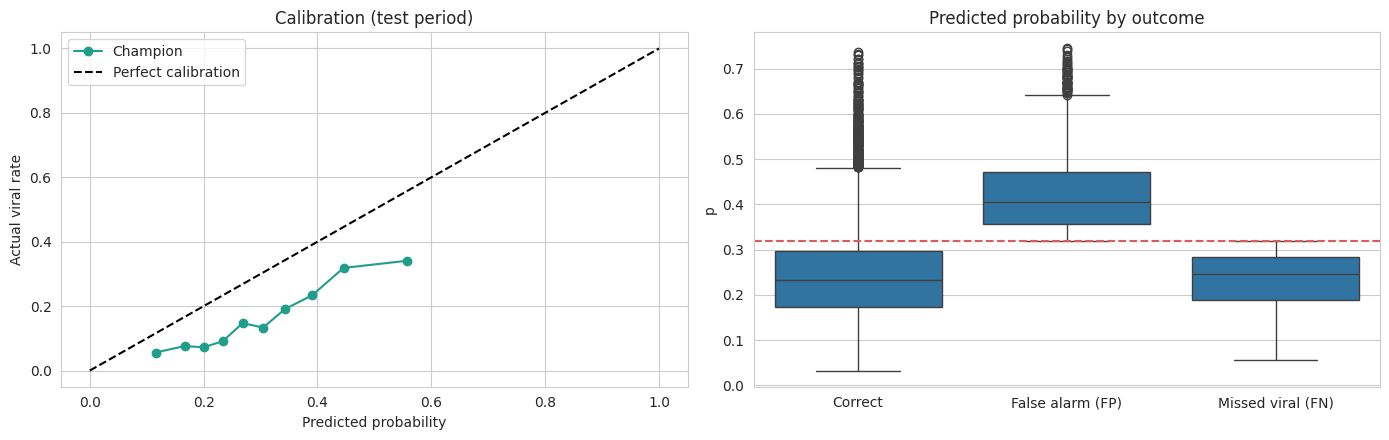

In [ ]:
err = test_df[['channel', 'day_type', 'shares', 'viral']].copy()
err['p'] = p_champ; err['pred'] = (p_champ >= THRESH).astype(int)
err['error_type'] = np.select([(err.viral == 1) & (err.pred == 0), (err.viral == 0) & (err.pred == 1)],
                              ['Missed viral (FN)', 'False alarm (FP)'], 'Correct')
by_ch = err.groupby('channel').apply(lambda d: pd.Series({
    'n': len(d), 'viral rate': d.viral.mean(),
    'PR-AUC': average_precision_score(d.viral, d.p) if d.viral.nunique() > 1 else np.nan,
    'ROC-AUC': roc_auc_score(d.viral, d.p) if d.viral.nunique() > 1 else np.nan,
    'recall': (d.pred[d.viral == 1] == 1).mean()})).sort_values('ROC-AUC')
display(by_ch.round(3))

fn = err[err.error_type == 'Missed viral (FN)']; tp = err[(err.viral == 1) & (err.pred == 1)]
print(f'Missed viral articles: {len(fn):,} | caught: {len(tp):,}')
print(f"Median shares of missed viral articles: {fn.shares.median():,.0f} vs caught viral articles: {tp.shares.median():,.0f}")
mega = err[err.shares >= err.shares.quantile(.99)]
print(f"Of the top-1% most-shared test articles ({len(mega)}), the model flagged {mega.pred.mean():.0%} as viral; "
      f"their median predicted probability was {mega.p.median():.2f} (overall median {err.p.median():.2f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
frac_pos, mean_pred = calibration_curve(y_test, p_champ, n_bins=10, strategy='quantile')
axes[0].plot(mean_pred, frac_pos, 'o-', color='#1f9e89', label='Champion'); axes[0].plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
axes[0].set_xlabel('Predicted probability'); axes[0].set_ylabel('Actual viral rate'); axes[0].set_title('Calibration (test period)'); axes[0].legend()
sns.boxplot(data=err, x='error_type', y='p', ax=axes[1], order=['Correct', 'False alarm (FP)', 'Missed viral (FN)'])
axes[1].axhline(THRESH, color='#e05a5a', ls='--'); axes[1].set_title('Predicted probability by outcome'); axes[1].set_xlabel('')
plt.tight_layout(); save_fig('error_analysis'); plt.show()

**Where it fails**

- **Unlabelled (`Other`) articles:** ROC-AUC only 0.51 — the model flags almost all of them as viral (recall 97 %) because the group as a whole goes viral often.
- It ranks best within Social Media (0.73), Business (0.69) and World (0.67).
- It **missed 464 of 1,330** viral test articles. Missed and caught hits have similar median shares (6,200 vs 6,400), so it does not only miss small hits. Of the 81 most-shared test articles (top 1 %), it flagged 67 %.
- The calibration curve shows probabilities are too high (class weighting inflates them), so scores should be read as a **ranking**, not literal probabilities.

**Why**

What makes a specific article explode — the news event itself, timing against competitors, an influencer sharing it — is not in the data. The model learns the *average* effect of topic and packaging, so it ranks groups of articles well but cannot pick individual winners.

### 8.5 Robustness and sanity checks

In [ ]:
def hgb():
    return make_champion()

rob = []
# (a) shuffled labels: if the model still "works", something is leaking
y_shuf = np.random.default_rng(0).permutation(y_train)
p = hgb().fit(X_train_c, y_shuf).predict_proba(X_test_c)[:, 1]
rob.append(['(a) Trained on shuffled labels', average_precision_score(y_test, p), roc_auc_score(y_test, p), y_test.mean()])
# (b) stricter definition of viral: top 10%
thr10 = train_df['shares'].quantile(.90); y10_tr, y10_te = (train_df.shares >= thr10).astype(int), (test_df.shares >= thr10).astype(int)
p = hgb().fit(X_train_c, y10_tr).predict_proba(X_test_c)[:, 1]
rob.append(['(b) Viral = top 10% instead of 20%', average_precision_score(y10_te, p), roc_auc_score(y10_te, p), y10_te.mean()])
# (c) random split instead of chronological
Xa, Xb, ya, yb = train_test_split(df[CONTROLLABLE], df['viral'], test_size=.2, stratify=df['viral'], random_state=RANDOM_STATE)
p = hgb().fit(Xa, ya).predict_proba(Xb)[:, 1]
rob.append(['(c) Random 80/20 split instead of time split', average_precision_score(yb, p), roc_auc_score(yb, p), yb.mean()])
# (d) different random seeds
seed_scores = [average_precision_score(y_test, make_champion(s).fit(X_train_c, y_train).predict_proba(X_test_c)[:, 1])
               for s in [0, 1, 2, 3, 4]]
rob.append([f'(d) 5 random seeds (PR-AUC SD = {np.std(seed_scores):.3f})', np.mean(seed_scores), np.nan, y_test.mean()])
rob_df = pd.DataFrame(rob, columns=['Check', 'PR-AUC', 'ROC-AUC', 'No-skill PR-AUC (positive rate)'])
rob_df['PR-AUC / no-skill'] = rob_df['PR-AUC'] / rob_df['No-skill PR-AUC (positive rate)']
display(rob_df.round(3))
RESULTS['robustness'] = rob_df.round(4).to_dict(orient='records')

,Check,PR-AUC,ROC-AUC,No-skill PR-AUC (positive rate),PR-AUC / no-skill
0,(a) Trained on shuffled labels,0.185,0.531,0.166,1.114
1,(b) Viral = top 10% instead of 20%,0.168,0.703,0.083,2.030
2,(c) Random 80/20 split instead of time split,0.323,0.681,0.197,1.642
3,(d) 5 random seeds (PR-AUC SD = 0.001),0.295,NaN,0.166,1.777


| Check | Result | Meaning |
|---|---|---|
| (a) Trained on shuffled labels | PR-AUC 0.188, ROC-AUC 0.53 | Collapses to ≈ no skill → the real signal is not an artefact (**criterion 3 met**) |
| (b) Viral = top 10 % | PR-AUC 0.168 vs 0.083 no-skill | Still about 2× no skill with a stricter definition |
| (c) Random split instead of time split | ROC-AUC 0.680 vs 0.695 | Results do not depend on the split method |
| (d) 5 random seeds | PR-AUC varies ± 0.002 | Results are stable |

## 9. Recommendations

A finding becomes a recommendation only if it passes criterion 4:

1. the recommended option is better **and** significant in the training period after Bonferroni correction, and
2. it is still better in the later test period.

**Strength:** *Strong* = also significant in the test period · *Weak* = same direction but not significant in the test period. The table is generated from the data, not written by hand.

In [ ]:
def compare(col, better, reference, label, action):
    out = {'Recommendation area': label, 'Compare': f'{better} vs {reference}', 'Suggested action': action}
    for name, d in [('train', train_df), ('test', test_df)]:
        a, b = d.loc[d[col] == better, 'viral'], d.loc[d[col] == reference, 'viral']
        out[f'{name} viral rate'] = f'{a.mean():.1%} vs {b.mean():.1%}'
        out[f'{name} lift'] = a.mean() / b.mean()
        out[f'{name} p'] = chi2_contingency([[a.sum(), len(a) - a.sum()], [b.sum(), len(b) - b.sum()]])[1]
    return out

candidates = [
    compare('day_type', 'Weekend', 'Weekday', 'Timing', 'Schedule flagship pieces for Saturday/Sunday'),
    compare('img_bin', '11+', '1', 'Images', 'Use image-rich layouts (6+ images); a single image does worst'),
    compare('video_bin', '2+', '0', 'Videos', 'Embed video when the story supports it'),
    compare('link_bin', '16+', '0-3', 'Links', 'Link generously to sources and related content'),
    compare('length_bin', '1000+', '251-500', 'Article length', 'Do not cut long-form pieces short just to be brief'),
    compare('channel', 'Social Media', 'World', 'Topic', 'Prioritise social-media/lifestyle topics over world news when the goal is shares'),
    compare('title_bin', '14+', '8-10', 'Title length', 'Title length — test only, do not change policy'),
]
rec = pd.DataFrame(candidates)
n_tests = len(rec)
# Pass = the recommended option is better (lift > 1) and significant in train after Bonferroni, AND still better in test.
rec['passes?'] = np.where((rec['train p'] * n_tests < 0.05) & (rec['train lift'] > 1) & (rec['test lift'] > 1), 'YES', 'no')
rec['strength'] = np.where(rec['passes?'] == 'no', '-', np.where(rec['test p'] < 0.05, 'Strong (significant in test too)',
                                                                 'Weak (same direction, not significant in test)'))
show = rec[['Recommendation area', 'Compare', 'train viral rate', 'train lift', 'train p', 'test viral rate', 'test lift', 'test p', 'passes?', 'strength', 'Suggested action']]
display(show.assign(**{'train p': show['train p'].map('{:.1e}'.format), 'test p': show['test p'].map('{:.1e}'.format)}).round(2))
rec.to_csv(f'{RES_DIR}/recommendations.csv', index=False)
RESULTS['recommendations'] = rec.round(4).to_dict(orient='records')

,Recommendation area,Compare,train viral rate,train lift,train p,test viral rate,test lift,test p,passes?,strength,Suggested action
0,Timing,Weekend vs Weekday,27.9% vs 19.4%,1.44,1.4e-36,23.3% vs 15.6%,1.49,6.3e-10,YES,Strong (significant in test too),Schedule flagship pieces for Saturday/Sunday
1,Images,11+ vs 1,27.4% vs 16.0%,1.71,2.7e-74,26.4% vs 11.2%,2.34,1.6e-30,YES,Strong (significant in test too),Use image-rich layouts (6+ images); a single i...
2,Videos,2+ vs 0,25.0% vs 18.7%,1.34,7.4e-20,17.3% vs 13.7%,1.26,2.8e-03,YES,Strong (significant in test too),Embed video when the story supports it
3,Links,16+ vs 0-3,27.6% vs 20.1%,1.38,2.0e-20,23.2% vs 18.5%,1.25,6.3e-04,YES,Strong (significant in test too),Link generously to sources and related content
4,Article length,1000+ vs 251-500,24.1% vs 19.0%,1.27,2.2e-11,16.4% vs 15.3%,1.07,4.2e-01,YES,"Weak (same direction, not significant in test)",Do not cut long-form pieces short just to be b...
5,Topic,Social Media vs World,29.4% vs 12.2%,2.42,5.5e-74,19.0% vs 9.4%,2.02,1.6e-05,YES,Strong (significant in test too),Prioritise social-media/lifestyle topics over ...
6,Title length,14+ vs 8-10,21.0% vs 20.7%,1.01,7.9e-01,17.4% vs 16.2%,1.07,3.9e-01,no,-,"Title length — test only, do not change policy"


**Result**

| Area | Recommendation | Train lift | Test lift | Strength |
|---|---|---|---|---|
| Topic | Prioritise social-media / lifestyle topics over world news when the goal is shares | 2.42× | 2.02× | Strong |
| Images | Use image-rich layouts (6+ images); a single image does worst | 1.71× | 2.34× | Strong |
| Timing | Schedule flagship pieces for Saturday / Sunday | 1.44× | 1.49× | Strong |
| Links | Link generously to sources and related content | 1.38× | 1.25× | Strong |
| Videos | Embed video when the story supports it | 1.34× | 1.26× | Strong |
| Article length | Don't cut long-form pieces short just to be brief | 1.27× | 1.07× | Weak |
| Title length | No recommendation — no real effect | 1.01× | 1.07× | Fails |

**How to use these:** each recommendation raises the *probability* of reaching the top 20 %; none guarantees it. Because this is observational data, confirm the top recommendations with a simple **A/B test** (e.g. randomly publish half of comparable pieces at weekends) before committing budget.

## 10. Limitations & conclusion

### 10.1 Limitations and risks

1. **News articles, not short videos.** Kickoff features such as video length, audio choice and posting **hour** are not in the data, so those questions remain open.
2. **Old data, one publisher.** Algorithms and audiences have changed since 2014, and Mashable's audience is tech-leaning. Re-test on current data before applying elsewhere.
3. **Association, not causation.** Weekend or image-rich articles may differ in ways we cannot see (e.g. editors saving their best stories for weekends). Only a randomised experiment can prove cause.
4. **Exposure time.** Test articles had been online for fewer days when collected (median 72 vs 427), which partly explains their lower viral rate.
5. **Possible leakage in history features.** `kw_*` statistics may use later articles, so all recommendations come from the creator-controllable model only.
6. **Luck dominates.** The best model explains only 11 % of the variation in shares (§7.1). It ranks articles better than chance but cannot predict which single article will explode.

### 10.2 Executive summary (generated from the results)

In [ ]:
champ_row = test_df_res[test_df_res['Model'].str.startswith('CHAMPION')].iloc[0]
lr_row = test_df_res[(test_df_res['Model'] == 'Logistic Regression') & (test_df_res['Feature set'] == 'Controllable')].iloc[0]
full_row = test_df_res[(test_df_res['Model'] == 'Random Forest') & (test_df_res['Feature set'] == 'Full (+history)')].iloc[0]
passed = rec[rec['passes?'] == 'YES']['Recommendation area'].tolist()
summary = f'''
PROBLEM   Which pre-posting content features predict whether an article goes viral (top 20% of shares, >= {VIRAL_THRESHOLD:,.0f})?
DATA      {len(df):,} real Mashable articles (UCI Online News Popularity), {len(CONTROLLABLE)} creator-controllable features;
          trained on articles before {cutoff.date()}, tested on the {len(test_df):,} most recent articles.
APPROACH  Baselines -> logistic regression -> random forest / gradient boosting; 5-fold CV to pick the model, then one final time-based test.
RESULTS   Champion ({CHAMP_NAME}, controllable features) on the later test period:
            PR-AUC {champ_row['PR-AUC']:.3f} vs no-skill {y_test.mean():.3f}; ROC-AUC {champ_row['ROC-AUC']:.3f} vs 0.5;
            top-10% scored articles go viral {champ_row['Precision @ top 10%']:.1%} of the time ({champ_row['Lift @ top 10%']:.1f}x the base rate).
          Logistic regression: PR-AUC {lr_row['PR-AUC']:.3f}. Adding platform-history features: PR-AUC {full_row['PR-AUC']:.3f}.
          When we shuffle the labels the score drops back to about no-skill, so the signal is real. Regression R^2 on log(shares) is only {reg_df.loc[2, 'R²']:.3f}.
INSIGHT   Topic matters the most. The other choices only change the odds a little. Most of virality can’t be predicted from these features.
RECOMMEND Recommendations that passed both checks were: {', '.join(passed) if passed else 'none'}.
          We should still run an A/B test before changing anything.
'''
print(summary)
RESULTS['summary'] = summary
with open(f'{RES_DIR}/results.json', 'w') as f:
    json.dump(RESULTS, f, indent=2, default=str)
print('Saved:', sorted(os.listdir(RES_DIR)), '| figures:', len(os.listdir(FIG_DIR)))


PROBLEM   Which pre-posting content features predict whether an article goes viral (top 20% of shares, >= 3,500)?
DATA      39,643 real Mashable articles (UCI Online News Popularity), 47 creator-controllable features;
          trained on articles before 2014-08-28, tested on the 8,006 most recent articles.
APPROACH  Baselines -> logistic regression -> random forest / gradient boosting; 5-fold CV to pick the model, then one final time-based test.
RESULTS   Champion (Random Forest, controllable features) on the later test period:
            PR-AUC 0.291 vs no-skill 0.166; ROC-AUC 0.696 vs 0.5;
            top-10% scored articles go viral 34.1% of the time (2.1x the base rate).
          Logistic regression: PR-AUC 0.301. Adding platform-history features: PR-AUC 0.338.
          When we shuffle the labels the score drops back to about no-skill, so the signal is real. Regression R^2 on log(shares) is only 0.112.
INSIGHT   Topic matters the most. The other choices only change the odds a 

### 10.3 Lessons learned

- **Check realism before modelling.** Our first dataset failed a simple histogram check; this one passed, and that decided the whole project.
- **Baselines make results honest.** "Never viral" is already 80 % accurate — PR-AUC against a no-skill line tells the real story.
- **Test winners on new data.** A later time period as the test set showed which patterns last.
- **Simple can be enough.** Logistic regression came close to the complex models.

### 10.4 Next steps

- Collect current short-video data with posting hour, duration and audio — the remaining kickoff questions.
- Run a small randomised posting experiment to test the top recommendations causally.